# EuroSAT Satellite Image Land-Use Classification

This notebook implements the complete Master 2 project workflow: a scratch-CNN baseline, controlled experiments, augmentation, transfer learning, final comparison, result export, checkpoint verification, and defense examples.

The notebook is designed for a Windows CPU-only laptop. It starts in `FAST_MODE = True`, which runs only small smoke tests. Full experiment sweeps remain disabled until the student turns them on deliberately.

**Academic integrity of the results:** smoke-test values are labeled as development checks and are not written to the final experiment table. Model selections remain empty until actual validation results exist.


## 0. Project Setup

This section imports the required libraries, finds the repository root, creates project-relative paths, fixes all random seeds, selects the CPU device, and defines safe execution controls.


### 0.1 Imports and package versions

This cell imports the standard scientific Python and PyTorch tools used throughout the notebook. Printing versions makes the environment easier to reproduce and diagnose during the defense.


In [56]:
import copy
import hashlib
import json
import os
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.10.16
PyTorch: 2.7.0+cpu
torchvision: 0.22.0+cpu
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1


**What to understand:**

- PyTorch and torchvision provide the model, dataset, transform, and optimization components.
- Recorded versions help explain environment-specific behavior if the notebook is run on another machine.


### 0.2 Project-relative paths

This cell locates the repository whether Jupyter starts from the project root or the `notebooks` folder. It then creates the required data, checkpoint, and results directories without using machine-specific paths.


In [57]:
def find_project_root(start_path=None):
    start_path = Path.cwd() if start_path is None else Path(start_path)
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "AGENTS.md").exists() and (candidate / "docs").exists():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Start Jupyter inside the EuroSAT_Project repository."
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
ORIGINAL_NOTEBOOK = NOTEBOOK_DIR / "EuroSAT_Project.ipynb"
RESULTS_CSV = RESULTS_DIR / "experiment_results.csv"

for directory in (DATA_DIR, CHECKPOINT_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file_handle:
        for block in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


ORIGINAL_NOTEBOOK_HASH_AT_START = sha256_file(ORIGINAL_NOTEBOOK)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR.relative_to(PROJECT_ROOT))
print("Checkpoint directory:", CHECKPOINT_DIR.relative_to(PROJECT_ROOT))
print("Results directory:", RESULTS_DIR.relative_to(PROJECT_ROOT))
print("Original notebook SHA-256:", ORIGINAL_NOTEBOOK_HASH_AT_START)


Project root: c:\Users\user\OneDrive - Lebanese University\Documents\GitHub\EuroSAT_Project
Data directory: data
Checkpoint directory: checkpoints
Results directory: results
Original notebook SHA-256: c3fcfafa588e77a748abe833f5c912d86b2ad96eaebdfbc5bb91102f8f95c814


**What to understand:**

- All paths are relative to the repository and therefore portable across Windows computers.
- The original notebook hash is recorded so the final validation can confirm that it was not modified.


### 0.3 Reproducibility and CPU device

This cell fixes Python, NumPy, and PyTorch random seeds and explicitly selects the CPU. The helper is called again before every independent experiment so model initialization and data order remain comparable.


In [58]:
SEED = 42
DEVICE = torch.device("cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed()
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

print("Device:", DEVICE)
print("PyTorch CPU threads:", torch.get_num_threads())


Device: cpu
PyTorch CPU threads: 4


**What to understand:**

- The device is always CPU; the notebook never assumes CUDA is available.
- Resetting the same seed before each run prevents one experiment from inheriting another run's random state.


### 0.4 Development and full-run controls

This cell separates lightweight validation settings from the documented full experiment settings. Long sweeps stay disabled even though `FAST_MODE` is enabled, so they cannot start accidentally.


In [113]:
FAST_MODE = False # Set to True for quick testing, False for full experiments

RUN_BASELINE_TRAINING = True
RUN_STAGE2_SWEEP = True
RUN_STAGE3_OPTIMIZER_SWEEP = False
RUN_STAGE3_SCHEDULER_COMPARISON = False
RUN_STAGE4_AUGMENTATION_SWEEP = False
RUN_FINAL_SCRATCH_TRAINING = False
RUN_TRANSFER_LEARNING_SWEEP = False
RUN_DATA_EFFICIENCY_EXPERIMENTS = False

FULL_SETTINGS = {
    "baseline_epochs": 10,
    "architecture_epochs": 8,
    "optimizer_epochs": 8,
    "augmentation_epochs": 8,
    "final_scratch_epochs": 15,
    "transfer_epochs": 5,
    "scratch_batch_size": 64,
    "transfer_batch_size": 16,
    "max_batches_per_epoch": None,
}

SMOKE_SETTINGS = {
    "baseline_epochs": 1,
    "architecture_epochs": 1,
    "optimizer_epochs": 1,
    "augmentation_epochs": 1,
    "final_scratch_epochs": 1,
    "transfer_epochs": 1,
    "scratch_batch_size": 32,
    "transfer_batch_size": 4,
    "max_batches_per_epoch": 2,
    "train_samples": 128,
    "val_samples": 64,
    "test_samples": 64,
}

ACTIVE_SETTINGS = SMOKE_SETTINGS if FAST_MODE else FULL_SETTINGS

print("FAST_MODE:", FAST_MODE)
print("Active settings:", ACTIVE_SETTINGS)
print("Full settings remain visible in FULL_SETTINGS.")


FAST_MODE: False
Active settings: {'baseline_epochs': 10, 'architecture_epochs': 8, 'optimizer_epochs': 8, 'augmentation_epochs': 8, 'final_scratch_epochs': 15, 'transfer_epochs': 5, 'scratch_batch_size': 64, 'transfer_batch_size': 16, 'max_batches_per_epoch': None}
Full settings remain visible in FULL_SETTINGS.


**What to understand:**

- `FAST_MODE=True` changes only the development workload and never represents a final experiment.
- Every expensive stage also has an explicit `RUN_...` switch that is currently `False`.


### 0.5 Experiment-results schema

This cell defines the single shared results table required by the project. The logging helper writes only real non-smoke experiments and preserves blank values for fields that do not apply.


In [60]:
RESULT_COLUMNS = [
    "experiment_id",
    "stage",
    "model_name",
    "architecture_change",
    "kernel_size",
    "stride",
    "padding",
    "batchnorm",
    "optimizer",
    "learning_rate",
    "scheduler",
    "augmentation",
    "epochs",
    "batch_size",
    "total_params",
    "trainable_params",
    "peak_val_accuracy",
    "final_train_accuracy",
    "final_val_accuracy",
    "final_val_loss",
    "test_accuracy",
    "runtime_seconds",
    "inference_latency_ms",
    "generalization_gap",
    "checkpoint",
    "notes",
]


def ensure_results_file():
    if not RESULTS_CSV.exists():
        pd.DataFrame(columns=RESULT_COLUMNS).to_csv(RESULTS_CSV, index=False)


def load_experiment_results():
    ensure_results_file()
    table = pd.read_csv(RESULTS_CSV)
    missing_columns = [column for column in RESULT_COLUMNS if column not in table.columns]
    if missing_columns:
        raise ValueError(f"Results CSV is missing columns: {missing_columns}")
    return table[RESULT_COLUMNS]


def append_experiment_result(record):
    if FAST_MODE:
        print("FAST_MODE result not written to the final experiment table.")
        return

    unknown_columns = set(record) - set(RESULT_COLUMNS)
    if unknown_columns:
        raise ValueError(f"Unknown result fields: {sorted(unknown_columns)}")

    table = load_experiment_results()
    row = {column: record.get(column, np.nan) for column in RESULT_COLUMNS}
    table = table[table["experiment_id"] != row["experiment_id"]]
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table.to_csv(RESULTS_CSV, index=False)
    print("Recorded experiment:", row["experiment_id"])


ensure_results_file()
experiment_results = load_experiment_results()
print("Results schema columns:", len(experiment_results.columns))
print("Recorded experiment rows:", len(experiment_results))


Results schema columns: 26
Recorded experiment rows: 0


**What to understand:**

- The CSV starts with the required header and contains no invented result rows.
- Smoke-test measurements stay in memory and cannot silently become report results.


## 1. Stage 1 - Common Dataset Pipeline and Baseline CNN

Stage 1 creates one reproducible EuroSAT split and a complete baseline workflow. Later controlled experiments reuse these same indices, evaluation helpers, and metric definitions.


### 1.1 Deterministic preprocessing transforms

This cell defines the 64×64 scratch-CNN preprocessing pipeline. Validation and test transforms contain no random operations, and the same normalization is used throughout scratch-model comparisons.


In [61]:
SCRATCH_IMAGE_SIZE = 64
SCRATCH_MEAN = (0.5, 0.5, 0.5)
SCRATCH_STD = (0.5, 0.5, 0.5)

scratch_eval_transform = transforms.Compose([
    transforms.Resize((SCRATCH_IMAGE_SIZE, SCRATCH_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(SCRATCH_MEAN, SCRATCH_STD),
])

scratch_no_augmentation_transform = transforms.Compose([
    transforms.Resize((SCRATCH_IMAGE_SIZE, SCRATCH_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(SCRATCH_MEAN, SCRATCH_STD),
])

print(scratch_eval_transform)


Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


**What to understand:**

- Scratch models keep the native 64×64 EuroSAT resolution to remain CPU-practical.
- Only the training transform will change during augmentation experiments.


### 1.2 Load EuroSAT and create the fixed split

This cell loads EuroSAT from the project `data/` folder and creates one fixed 70/15/15 split. The resulting indices are the authoritative split for every scratch and transfer-learning experiment.


In [62]:
extracted_dataset_path = DATA_DIR / "eurosat" / "2750"
should_download = not extracted_dataset_path.exists()

base_dataset = datasets.EuroSAT(
    root=DATA_DIR,
    download=should_download,
)

CLASS_NAMES = list(base_dataset.classes)
NUM_CLASSES = len(CLASS_NAMES)

split_generator = torch.Generator().manual_seed(SEED)
shuffled_indices = torch.randperm(len(base_dataset), generator=split_generator).tolist()

train_count = int(0.70 * len(shuffled_indices))
val_count = int(0.15 * len(shuffled_indices))

TRAIN_INDICES = shuffled_indices[:train_count]
VAL_INDICES = shuffled_indices[train_count:train_count + val_count]
TEST_INDICES = shuffled_indices[train_count + val_count:]

assert len(TRAIN_INDICES) + len(VAL_INDICES) + len(TEST_INDICES) == len(base_dataset)
assert len(set(TRAIN_INDICES) | set(VAL_INDICES) | set(TEST_INDICES)) == len(base_dataset)

print("Dataset size:", len(base_dataset))
print("Classes:", CLASS_NAMES)
print("Train / validation / test:", len(TRAIN_INDICES), len(VAL_INDICES), len(TEST_INDICES))


Dataset size: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Train / validation / test: 18900 4050 4050


**What to understand:**

- The test indices are reserved and never used to select architecture, optimizer, scheduler, or augmentation.
- All later transforms are applied to new dataset views that reuse these exact indices.


### 1.3 Dataset-view and DataLoader helpers

This cell builds separate dataset objects for training and evaluation transforms while keeping the same split indices. `num_workers=0` is used for reliable Windows CPU execution.


In [63]:
def limited_indices(indices, limit=None):
    if limit is None:
        return list(indices)
    return list(indices[: min(limit, len(indices))])


def make_dataset_subset(transform, indices, limit=None):
    dataset_view = datasets.EuroSAT(
        root=DATA_DIR,
        download=False,
        transform=transform,
    )
    return Subset(dataset_view, limited_indices(indices, limit))


def make_scratch_loaders(train_transform, batch_size=None, train_fraction=1.0):
    batch_size = batch_size or ACTIVE_SETTINGS["scratch_batch_size"]

    if FAST_MODE:
        train_limit = ACTIVE_SETTINGS["train_samples"]
        val_limit = ACTIVE_SETTINGS["val_samples"]
        test_limit = ACTIVE_SETTINGS["test_samples"]
    else:
        train_limit = max(1, int(len(TRAIN_INDICES) * train_fraction))
        val_limit = None
        test_limit = None

    train_subset = make_dataset_subset(train_transform, TRAIN_INDICES, train_limit)
    val_subset = make_dataset_subset(scratch_eval_transform, VAL_INDICES, val_limit)
    test_subset = make_dataset_subset(scratch_eval_transform, TEST_INDICES, test_limit)

    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=False,
        generator=loader_generator,
    )
    val_loader = DataLoader(
        val_subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    )
    test_loader = DataLoader(
        test_subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    )
    return train_loader, val_loader, test_loader


**What to understand:**

- Separate dataset views prevent random training augmentation from leaking into validation or test data.
- The fixed indices remain unchanged even when FAST_MODE temporarily uses only the beginning of each split.


### 1.4 Create the baseline loaders

This cell creates the no-augmentation baseline loaders and prints their batch shapes. These loaders are small in FAST_MODE and use the full fixed split when FAST_MODE is disabled.


In [64]:
train_loader, val_loader, test_loader = make_scratch_loaders(
    train_transform=scratch_no_augmentation_transform,
    batch_size=ACTIVE_SETTINGS["scratch_batch_size"],
)

sample_images, sample_labels = next(iter(train_loader))

print("Train / validation / test samples:",
      len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
assert sample_images.ndim == 4 and sample_images.shape[1:] == (3, 64, 64)


Train / validation / test samples: 18900 4050 4050
Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


**What to understand:**

- Image tensors use `[batch, channels, height, width]` ordering.
- Training is shuffled; validation and test loaders keep a stable order.


### 1.5 Visualize normalized training samples

This cell reverses the scratch normalization before displaying images. Correct unnormalization prevents the washed-out visualization produced by applying an unnecessary offset.


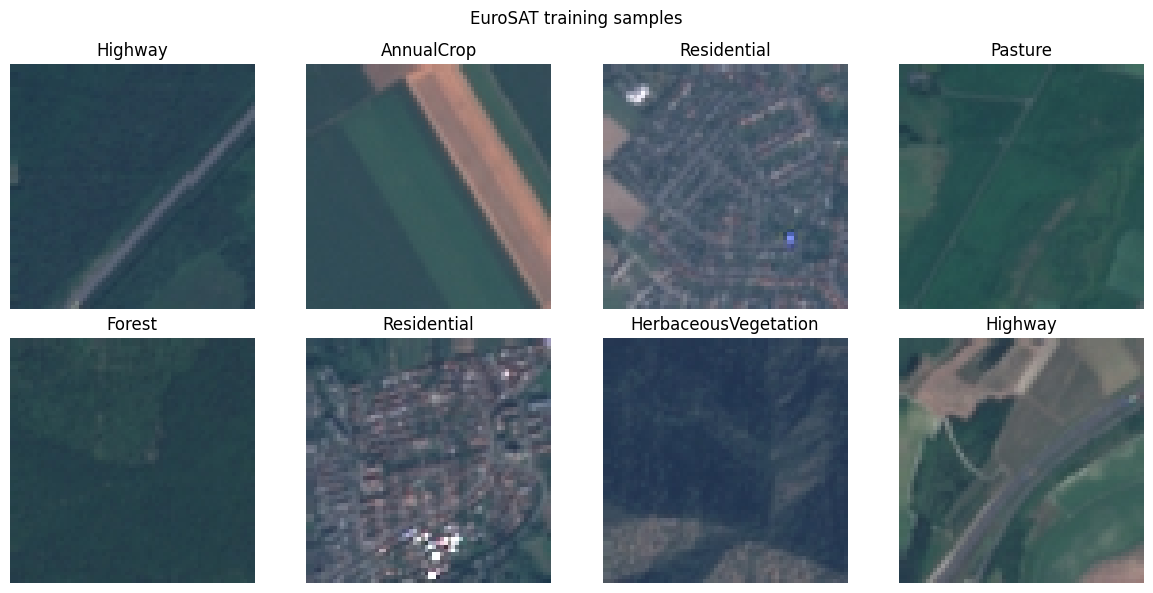

In [65]:
def unnormalize_scratch_image(image_tensor):
    mean = torch.tensor(SCRATCH_MEAN).view(3, 1, 1)
    std = torch.tensor(SCRATCH_STD).view(3, 1, 1)
    return (image_tensor.cpu() * std + mean).clamp(0, 1)


def show_image_batch(images, labels, class_names, max_images=8, title=None):
    count = min(max_images, len(images))
    figure, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.flatten()

    for index, axis in enumerate(axes):
        axis.axis("off")
        if index < count:
            image = unnormalize_scratch_image(images[index])
            axis.imshow(image.permute(1, 2, 0).numpy())
            axis.set_title(class_names[int(labels[index])])

    if title:
        figure.suptitle(title)
    plt.tight_layout()
    plt.show()


show_image_batch(
    sample_images,
    sample_labels,
    CLASS_NAMES,
    title="EuroSAT training samples",
)


**What to understand:**

- Normalization changes the numeric tensor values, so visualization must reverse it.
- The displayed labels provide a quick check that images and targets remain aligned.


### 1.6 Configurable scratch CNN

This cell defines a readable CNN that supports the required architecture comparisons. The convolutional blocks remain explicit, while adaptive pooling gives a fixed classifier input size across controlled depth and stride changes.


In [66]:
def make_activation(activation_name):
    if activation_name == "relu":
        return nn.ReLU()
    if activation_name == "leaky_relu":
        return nn.LeakyReLU(negative_slope=0.1)
    if activation_name == "elu":
        return nn.ELU()
    raise ValueError(f"Unsupported activation: {activation_name}")


class ScratchCNN(nn.Module):
    def __init__(
        self,
        num_classes=10,
        conv_channels=(32, 64, 128),
        kernel_size=3,
        stride=1,
        padding=1,
        use_batchnorm=False,
        activation="relu",
    ):
        super().__init__()

        layers = []
        input_channels = 3

        for block_index, output_channels in enumerate(conv_channels):
            block_stride = stride if block_index == 0 else 1
            layers.append(
                nn.Conv2d(
                    input_channels,
                    output_channels,
                    kernel_size=kernel_size,
                    stride=block_stride,
                    padding=padding,
                )
            )
            if use_batchnorm:
                layers.append(nn.BatchNorm2d(output_channels))
            layers.append(make_activation(activation))
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            input_channels = output_channels

        self.features = nn.Sequential(*layers)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(conv_channels[-1] * 4 * 4, 128),
            make_activation(activation),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = self.classifier(x)
        return x


def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )
    return total, trainable


**What to understand:**

- Every model still subclasses `nn.Module`, defines layers in `__init__`, and performs computation in `forward`.
- Adaptive pooling changes only the handoff to the classifier; convolution shapes are still inspected explicitly.


### 1.7 Baseline model and forward-pass shape check

This cell creates the three-block baseline, counts its parameters, and verifies that a CPU forward pass returns one score for each of the 10 classes.


In [67]:
BASELINE_MODEL_CONFIG = {
    "num_classes": NUM_CLASSES,
    "conv_channels": (32, 64, 128),
    "kernel_size": 3,
    "stride": 1,
    "padding": 1,
    "use_batchnorm": False,
    "activation": "relu",
}

set_seed()
baseline_model = ScratchCNN(**BASELINE_MODEL_CONFIG).to(DEVICE)
baseline_total_params, baseline_trainable_params = count_parameters(baseline_model)

with torch.no_grad():
    baseline_output = baseline_model(sample_images[:4].to(DEVICE))

print(baseline_model)
print("Total parameters:", baseline_total_params)
print("Trainable parameters:", baseline_trainable_params)
print("Forward-pass output shape:", baseline_output.shape)
assert baseline_output.shape == (4, NUM_CLASSES)


ScratchCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Total parameters: 356810
Trainable parameters: 356810
Forward-pass output shape: torch.Size([4, 10])


**What to understand:**

- The final dimension is 10 because EuroSAT has 10 land-use classes.
- Parameter counts will be recorded for every controlled experiment.


### 1.8 Training and evaluation functions

This cell defines reusable loops that follow the instructor's PyTorch order. Evaluation always uses `model.eval()` and `torch.no_grad()`, and optional MixUp is applied to tensor batches rather than PIL images.


In [68]:
def apply_mixup(inputs, labels, alpha):
    if alpha is None or alpha <= 0:
        return inputs, labels, labels, 1.0

    mixing_weight = float(np.random.beta(alpha, alpha))
    permutation = torch.randperm(inputs.size(0), device=inputs.device)
    mixed_inputs = mixing_weight * inputs + (1.0 - mixing_weight) * inputs[permutation]
    return mixed_inputs, labels, labels[permutation], mixing_weight


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device=DEVICE,
    mixup_alpha=None,
    max_batches=None,
):
    model.train()
    running_loss = 0.0
    running_correct = 0.0
    sample_count = 0

    for batch_index, (inputs, labels) in enumerate(loader):
        if max_batches is not None and batch_index >= max_batches:
            break

        inputs = inputs.to(device)
        labels = labels.to(device)
        inputs, labels_a, labels_b, mixing_weight = apply_mixup(
            inputs, labels, mixup_alpha
        )

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = (
            mixing_weight * criterion(outputs, labels_a)
            + (1.0 - mixing_weight) * criterion(outputs, labels_b)
        )
        loss.backward()
        optimizer.step()

        predicted = outputs.argmax(dim=1)
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_correct += (
            mixing_weight * (predicted == labels_a).sum().item()
            + (1.0 - mixing_weight) * (predicted == labels_b).sum().item()
        )
        sample_count += batch_size

    return {
        "loss": running_loss / sample_count,
        "accuracy": running_correct / sample_count,
    }


def evaluate_model(
    model,
    loader,
    criterion,
    device=DEVICE,
    max_batches=None,
    collect_predictions=False,
):
    model.eval()
    running_loss = 0.0
    correct = 0
    sample_count = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch_index, (inputs, labels) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break

            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            predicted = outputs.argmax(dim=1)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            correct += (predicted == labels).sum().item()
            sample_count += batch_size

            if collect_predictions:
                all_labels.extend(labels.cpu().tolist())
                all_predictions.extend(predicted.cpu().tolist())

    metrics = {
        "loss": running_loss / sample_count,
        "accuracy": correct / sample_count,
    }
    if collect_predictions:
        metrics["labels"] = all_labels
        metrics["predictions"] = all_predictions
    return metrics


def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    checkpoint_path,
    scheduler=None,
    mixup_alpha=None,
    max_batches=None,
):
    history = {
        "epoch": [],
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "learning_rate": [],
    }
    best_val_accuracy = -1.0
    best_state = None
    start_time = time.perf_counter()

    for epoch in range(epochs):
        train_metrics = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            mixup_alpha=mixup_alpha,
            max_batches=max_batches,
        )
        val_metrics = evaluate_model(
            model,
            val_loader,
            criterion,
            max_batches=max_batches,
        )

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["learning_rate"].append(optimizer.param_groups[0]["lr"])

        if val_metrics["accuracy"] > best_val_accuracy:
            best_val_accuracy = val_metrics["accuracy"]
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }

        if scheduler is not None:
            scheduler.step()

        print(
            f"Epoch {epoch + 1:02d}/{epochs:02d} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"train accuracy {100 * train_metrics['accuracy']:.2f}% | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val accuracy {100 * val_metrics['accuracy']:.2f}%"
        )

    runtime_seconds = time.perf_counter() - start_time
    model.load_state_dict(best_state)
    torch.save(best_state, checkpoint_path)
    return history, runtime_seconds


**What to understand:**

- The training order is `zero_grad` → forward → loss → `backward` → optimizer step.
- The checkpoint stores only the best validation `state_dict`, not a pickled model object.
- MixUp training accuracy is a weighted diagnostic because each sample has two target labels.


### 1.9 Diagnostic, plotting, and artifact helpers

This cell defines the reusable metrics required by the assignment: learning curves, per-class accuracy, normalized confusion matrices, inference latency, and clean CSV artifacts.


In [69]:
def plot_learning_curves(history, title_prefix="Model"):
    epochs = history["epoch"]
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title_prefix}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_accuracy"], label="Training accuracy")
    axes[1].plot(epochs, history["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(f"{title_prefix}: accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def per_class_accuracy(labels, predictions, class_names=CLASS_NAMES):
    rows = []
    labels = np.asarray(labels)
    predictions = np.asarray(predictions)

    for class_index, class_name in enumerate(class_names):
        class_mask = labels == class_index
        sample_count = int(class_mask.sum())
        accuracy = (
            float((predictions[class_mask] == class_index).mean())
            if sample_count > 0
            else np.nan
        )
        rows.append({
            "class_index": class_index,
            "class_name": class_name,
            "samples": sample_count,
            "accuracy": accuracy,
        })
    return pd.DataFrame(rows)


def plot_normalized_confusion_matrix(labels, predictions, class_names, title):
    matrix = confusion_matrix(
        labels,
        predictions,
        labels=list(range(len(class_names))),
        normalize="true",
    )
    figure, axis = plt.subplots(figsize=(9, 8))
    image = axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    figure.colorbar(image, ax=axis)
    axis.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right")
    axis.set_yticks(range(len(class_names)), class_names)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    axis.set_title(title)
    plt.tight_layout()
    plt.show()
    return matrix


def measure_inference_latency_ms(model, loader, iterations=5):
    model.eval()
    inputs, _ = next(iter(loader))
    inputs = inputs.to(DEVICE)

    with torch.no_grad():
        _ = model(inputs)
        start_time = time.perf_counter()
        for _ in range(iterations):
            _ = model(inputs)
        elapsed = time.perf_counter() - start_time

    return 1000.0 * elapsed / (iterations * inputs.size(0))


def save_history(history, experiment_id):
    history_path = RESULTS_DIR / f"{experiment_id}_history.csv"
    pd.DataFrame(history).to_csv(history_path, index=False)
    return history_path


def save_evaluation_artifacts(experiment_id, evaluation):
    class_table = per_class_accuracy(
        evaluation["labels"], evaluation["predictions"]
    )
    class_path = RESULTS_DIR / f"{experiment_id}_per_class.csv"
    class_table.to_csv(class_path, index=False)

    matrix = confusion_matrix(
        evaluation["labels"],
        evaluation["predictions"],
        labels=list(range(NUM_CLASSES)),
        normalize="true",
    )
    matrix_path = RESULTS_DIR / f"{experiment_id}_confusion_matrix.csv"
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(matrix_path)
    return class_path, matrix_path


**What to understand:**

- Latency is reported as average CPU milliseconds per image for the measured mini-batch.
- Per-class and confusion-matrix files are exported only from real executed evaluations.


### 1.10 Baseline CPU smoke training

This cell runs the only training enabled by default. In FAST_MODE it processes at most two training and validation batches for one epoch and saves a clearly named smoke checkpoint.


In [70]:
baseline_artifacts = None

if RUN_BASELINE_TRAINING:
    set_seed()
    baseline_model = ScratchCNN(**BASELINE_MODEL_CONFIG).to(DEVICE)
    baseline_criterion = nn.CrossEntropyLoss()
    baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3)

    baseline_checkpoint = CHECKPOINT_DIR / (
        "smoke_baseline.pth" if FAST_MODE else "baseline.pth"
    )
    baseline_epochs = ACTIVE_SETTINGS["baseline_epochs"]

    baseline_history, baseline_runtime = fit_model(
        baseline_model,
        train_loader,
        val_loader,
        baseline_criterion,
        baseline_optimizer,
        epochs=baseline_epochs,
        checkpoint_path=baseline_checkpoint,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
    )

    baseline_test_metrics = evaluate_model(
        baseline_model,
        test_loader,
        baseline_criterion,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
        collect_predictions=True,
    )
    baseline_latency = measure_inference_latency_ms(baseline_model, test_loader)

    baseline_artifacts = {
        "model": baseline_model,
        "history": baseline_history,
        "runtime_seconds": baseline_runtime,
        "test_metrics": baseline_test_metrics,
        "latency_ms": baseline_latency,
        "checkpoint": baseline_checkpoint,
    }

    print("Checkpoint:", baseline_checkpoint.relative_to(PROJECT_ROOT))
    print("Test accuracy:", f"{100 * baseline_test_metrics['accuracy']:.2f}%")
    print("CPU latency per image:", f"{baseline_latency:.3f} ms")
else:
    print("Baseline training is disabled.")


Epoch 01/10 | train loss 1.3043 | train accuracy 49.97% | val loss 0.9979 | val accuracy 64.00%
Epoch 02/10 | train loss 0.7997 | train accuracy 70.49% | val loss 0.6814 | val accuracy 75.43%
Epoch 03/10 | train loss 0.6461 | train accuracy 76.41% | val loss 0.6603 | val accuracy 76.10%
Epoch 04/10 | train loss 0.5663 | train accuracy 79.71% | val loss 0.5293 | val accuracy 80.79%
Epoch 05/10 | train loss 0.5191 | train accuracy 81.23% | val loss 0.4952 | val accuracy 81.60%
Epoch 06/10 | train loss 0.4652 | train accuracy 83.33% | val loss 0.5057 | val accuracy 81.31%
Epoch 07/10 | train loss 0.4268 | train accuracy 84.63% | val loss 0.4631 | val accuracy 83.26%
Epoch 08/10 | train loss 0.3813 | train accuracy 86.15% | val loss 0.4287 | val accuracy 85.36%
Epoch 09/10 | train loss 0.3582 | train accuracy 87.02% | val loss 0.4113 | val accuracy 85.16%
Epoch 10/10 | train loss 0.3358 | train accuracy 88.07% | val loss 0.3560 | val accuracy 87.51%
Checkpoint: checkpoints\baseline.pth
Tes

**What to understand:**

- `smoke_baseline.pth` proves the pipeline works without pretending to be the required full baseline checkpoint.
- The full run will use `checkpoints/baseline.pth` only after FAST_MODE is disabled.


### 1.11 Baseline diagnostics and result integrity

This cell displays the baseline learning curves, per-class accuracy, and normalized confusion matrix when training has run. FAST_MODE outputs are explicitly labeled and are not appended to the final experiment CSV.


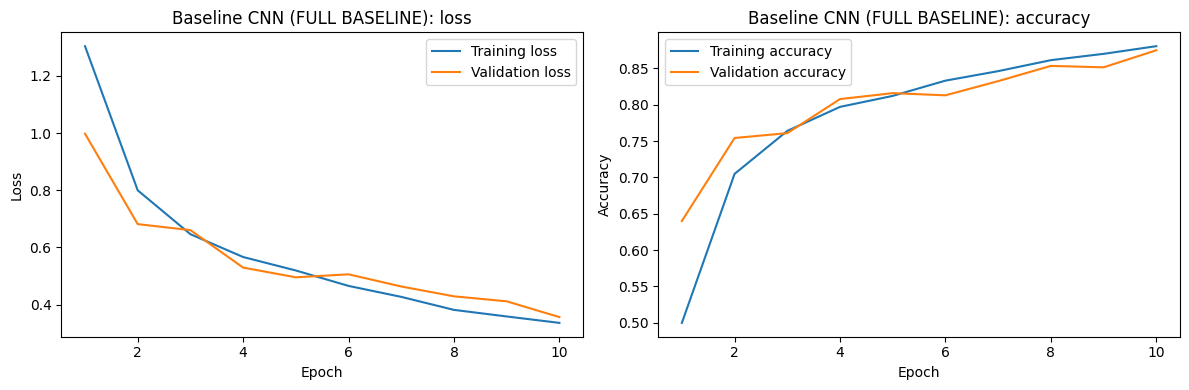

,class_index,class_name,samples,accuracy
0,0,AnnualCrop,472,0.860169
1,1,Forest,442,0.864253
2,2,HerbaceousVegetation,458,0.744541
3,3,Highway,391,0.810742
4,4,Industrial,378,0.933862
5,5,Pasture,299,0.903010
6,6,PermanentCrop,379,0.875989
7,7,Residential,450,0.964444
8,8,River,375,0.898667
9,9,SeaLake,406,0.965517


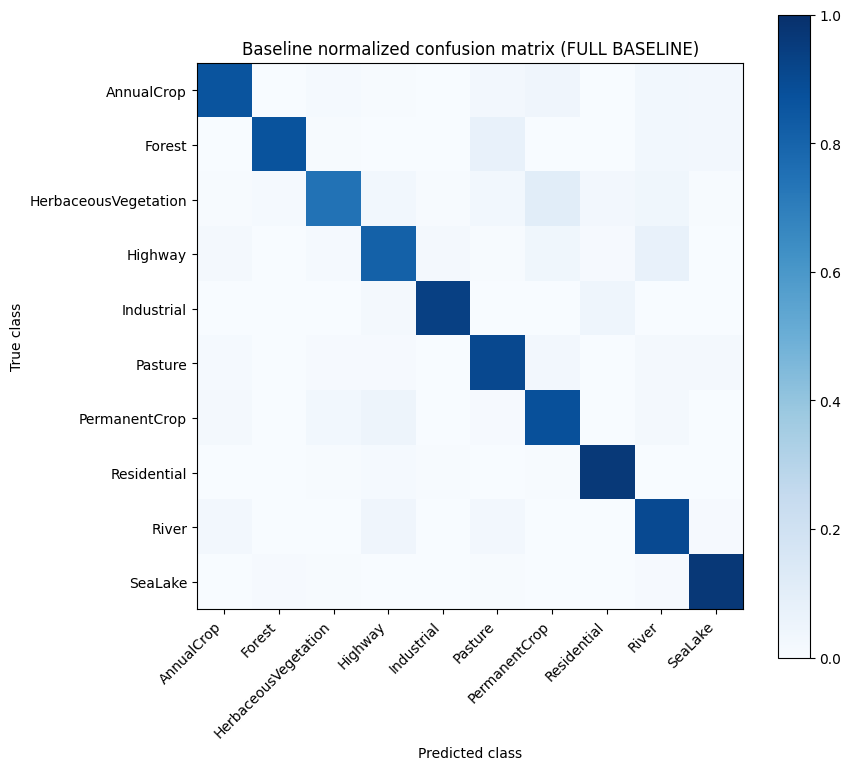

Recorded experiment: S1_BASELINE


C:\Users\user\AppData\Local\Temp\ipykernel_15212\1583369374.py:57: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)


In [71]:
if baseline_artifacts is not None:
    mode_label = "SMOKE TEST" if FAST_MODE else "FULL BASELINE"
    plot_learning_curves(
        baseline_artifacts["history"],
        title_prefix=f"Baseline CNN ({mode_label})",
    )

    baseline_class_table = per_class_accuracy(
        baseline_artifacts["test_metrics"]["labels"],
        baseline_artifacts["test_metrics"]["predictions"],
    )
    display(baseline_class_table)

    baseline_confusion_matrix = plot_normalized_confusion_matrix(
        baseline_artifacts["test_metrics"]["labels"],
        baseline_artifacts["test_metrics"]["predictions"],
        CLASS_NAMES,
        title=f"Baseline normalized confusion matrix ({mode_label})",
    )

    if not FAST_MODE:
        append_experiment_result({
            "experiment_id": "S1_BASELINE",
            "stage": 1,
            "model_name": "baseline_cnn",
            "architecture_change": "three convolutional blocks",
            "kernel_size": 3,
            "stride": 1,
            "padding": 1,
            "batchnorm": False,
            "optimizer": "Adam",
            "learning_rate": 1e-3,
            "scheduler": "none",
            "augmentation": "none",
            "epochs": FULL_SETTINGS["baseline_epochs"],
            "batch_size": FULL_SETTINGS["scratch_batch_size"],
            "total_params": baseline_total_params,
            "trainable_params": baseline_trainable_params,
            "peak_val_accuracy": max(baseline_artifacts["history"]["val_accuracy"]),
            "final_train_accuracy": baseline_artifacts["history"]["train_accuracy"][-1],
            "final_val_accuracy": baseline_artifacts["history"]["val_accuracy"][-1],
            "final_val_loss": baseline_artifacts["history"]["val_loss"][-1],
            "test_accuracy": baseline_artifacts["test_metrics"]["accuracy"],
            "runtime_seconds": baseline_artifacts["runtime_seconds"],
            "inference_latency_ms": baseline_artifacts["latency_ms"],
            "generalization_gap": (
                baseline_artifacts["history"]["train_accuracy"][-1]
                - baseline_artifacts["history"]["val_accuracy"][-1]
            ),
            "checkpoint": "checkpoints/baseline.pth",
            "notes": "Baseline test diagnostics are not used for later model selection.",
        })
        save_history(baseline_artifacts["history"], "S1_BASELINE")
        save_evaluation_artifacts("S1_BASELINE", baseline_artifacts["test_metrics"])
    else:
        print("Development-only metrics shown above; no final CSV row was written.")


**What to understand:**

- Baseline test reporting is permitted, but those test results must not guide later choices.
- A real result row is created only when `FAST_MODE=False`.


### 1.12 Baseline result summary

This cell prints a compact factual summary of the executed baseline run. It never supplies a result when the corresponding code has not run.


In [72]:
if baseline_artifacts is None:
    print("No baseline run is available.")
else:
    print("=" * 50)
    print("STAGE 1 BASELINE", "SMOKE TEST" if FAST_MODE else "FULL RUN")
    print("=" * 50)
    print("Model: three-block scratch CNN")
    print("Image size:", SCRATCH_IMAGE_SIZE)
    print("Epochs executed:", len(baseline_artifacts["history"]["epoch"]))
    print("Peak validation accuracy:",
          f"{100 * max(baseline_artifacts['history']['val_accuracy']):.2f}%")
    print("Test accuracy:",
          f"{100 * baseline_artifacts['test_metrics']['accuracy']:.2f}%")
    print("Runtime:", f"{baseline_artifacts['runtime_seconds']:.2f} seconds")
    print("Checkpoint:", baseline_artifacts["checkpoint"].relative_to(PROJECT_ROOT))


STAGE 1 BASELINE FULL RUN
Model: three-block scratch CNN
Image size: 64
Epochs executed: 10
Peak validation accuracy: 87.51%
Test accuracy: 88.00%
Runtime: 974.88 seconds
Checkpoint: checkpoints\baseline.pth


**What to understand:**

- Displayed numbers come only from the current executed run.
- FAST_MODE results are development evidence, not conclusions for the report.


## 2. Stage 2 - Controlled Architecture Experiments

These experiments change one architectural factor at a time. All runs use the fixed split, 64×64 preprocessing, Adam at `1e-3`, no augmentation, the same epoch budget, and freshly initialized weights.

**Long experiment section:** `RUN_STAGE2_SWEEP` remains `False` by default.


### 2.1 Architecture experiment definitions

This cell defines the required depth, kernel-size, BatchNorm, and stride/padding comparisons. Each definition states the intended change while preserving the other baseline settings.


In [110]:
def scratch_config(
    conv_channels=(32, 64, 128),
    kernel_size=3,
    stride=1,
    padding=1,
    use_batchnorm=False,
    activation="relu",
):
    return {
        "num_classes": NUM_CLASSES,
        "conv_channels": tuple(conv_channels),
        "kernel_size": kernel_size,
        "stride": stride,
        "padding": padding,
        "use_batchnorm": use_batchnorm,
        "activation": activation,
    }


STAGE2_EXPERIMENTS = [
    {"experiment_id": "S2_DEPTH_2", "change": "2 convolutional blocks",
     "model_config": scratch_config((32, 64))},
    {"experiment_id": "S2_DEPTH_3", "change": "3 convolutional blocks",
     "model_config": scratch_config((32, 64, 128))},
    {"experiment_id": "S2_DEPTH_4", "change": "4 convolutional blocks",
     "model_config": scratch_config((32, 64, 128, 256))},
    {"experiment_id": "S2_KERNEL_3", "change": "3x3 kernels",
     "model_config": scratch_config(kernel_size=3, padding=1)},
    {"experiment_id": "S2_KERNEL_5", "change": "5x5 kernels",
     "model_config": scratch_config(kernel_size=5, padding=2)},
    {"experiment_id": "S2_KERNEL_7", "change": "7x7 kernels",
     "model_config": scratch_config(kernel_size=7, padding=3)},
    {"experiment_id": "S2_BN_OFF", "change": "BatchNorm disabled",
     "model_config": scratch_config(use_batchnorm=False)},
    {"experiment_id": "S2_BN_ON", "change": "BatchNorm enabled",
     "model_config": scratch_config(use_batchnorm=True)},
    {"experiment_id": "S2_STRIDE1_PAD1", "change": "stride 1, padding 1 control",
     "model_config": scratch_config(stride=1, padding=1)},
    {"experiment_id": "S2_STRIDE2_PAD1", "change": "first convolution stride 2",
     "model_config": scratch_config(stride=2, padding=1)},
    {"experiment_id": "S2_STRIDE1_PAD0", "change": "no convolution padding",
     "model_config": scratch_config(stride=1, padding=0)},
]

stage2_plan = pd.DataFrame([
    {
        "experiment_id": item["experiment_id"],
        "architecture_change": item["change"],
        "depth": len(item["model_config"]["conv_channels"]),
        "kernel_size": item["model_config"]["kernel_size"],
        "stride": item["model_config"]["stride"],
        "padding": item["model_config"]["padding"],
        "batchnorm": item["model_config"]["use_batchnorm"],
    }
    for item in STAGE2_EXPERIMENTS
])
display(stage2_plan)


,experiment_id,architecture_change,depth,kernel_size,stride,padding,batchnorm
0,S2_DEPTH_2,2 convolutional blocks,2,3,1,1,False
1,S2_DEPTH_3,3 convolutional blocks,3,3,1,1,False
2,S2_DEPTH_4,4 convolutional blocks,4,3,1,1,False
3,S2_KERNEL_3,3x3 kernels,3,3,1,1,False
4,S2_KERNEL_5,5x5 kernels,3,5,1,2,False
5,S2_KERNEL_7,7x7 kernels,3,7,1,3,False
6,S2_BN_OFF,BatchNorm disabled,3,3,1,1,False
7,S2_BN_ON,BatchNorm enabled,3,3,1,1,True
8,S2_STRIDE1_PAD1,"stride 1, padding 1 control",3,3,1,1,False
9,S2_STRIDE2_PAD1,first convolution stride 2,3,3,2,1,False


**What to understand:**

- Depth, kernel, BatchNorm, and stride/padding each have their own controlled comparison group.
- Adaptive pooling keeps the classifier interface fixed while the tested convolution settings change.


### 2.2 Optimizer builder and scratch experiment runner

This cell defines one reusable experiment function so all scratch comparisons use the same training, validation, timing, checkpoint, and logging procedure.


In [111]:
def build_optimizer(model, optimizer_name, learning_rate, momentum=0.9):
    if optimizer_name == "SGD":
        return optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=momentum,
        )
    if optimizer_name == "Adam":
        return optim.Adam(model.parameters(), lr=learning_rate)
    if optimizer_name == "AdamW":
        return optim.AdamW(model.parameters(), lr=learning_rate)
    raise ValueError(f"Unsupported optimizer: {optimizer_name}")


def run_scratch_experiment(
    experiment_id,
    stage,
    model_config,
    architecture_change,
    optimizer_name="Adam",
    learning_rate=1e-3,
    scheduler_name="none",
    augmentation_name="none",
    train_transform=None,
    mixup_alpha=None,
    epochs=None,
    checkpoint_filename=None,
):
    set_seed()
    train_transform = train_transform or scratch_no_augmentation_transform
    batch_size = ACTIVE_SETTINGS["scratch_batch_size"]
    experiment_train_loader, experiment_val_loader, _ = make_scratch_loaders(
        train_transform=train_transform,
        batch_size=batch_size,
    )

    model = ScratchCNN(**model_config).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, optimizer_name, learning_rate)

    scheduler = None
    if scheduler_name == "StepLR":
        scheduler = optim.lr_scheduler.StepLR(
            optimizer,
            step_size=max(1, epochs // 3),
            gamma=0.1,
        )
    elif scheduler_name != "none":
        raise ValueError(f"Unsupported scheduler: {scheduler_name}")

    checkpoint_filename = checkpoint_filename or f"{experiment_id.lower()}.pth"
    if FAST_MODE:
        checkpoint_filename = f"smoke_{checkpoint_filename}"
    checkpoint_path = CHECKPOINT_DIR / checkpoint_filename

    history, runtime_seconds = fit_model(
        model,
        experiment_train_loader,
        experiment_val_loader,
        criterion,
        optimizer,
        epochs=epochs,
        checkpoint_path=checkpoint_path,
        scheduler=scheduler,
        mixup_alpha=mixup_alpha,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
    )

    total_params, trainable_params = count_parameters(model)
    latency_ms = measure_inference_latency_ms(model, experiment_val_loader)
    result = {
        "experiment_id": experiment_id,
        "stage": stage,
        "model_name": "scratch_cnn",
        "architecture_change": architecture_change,
        "kernel_size": model_config["kernel_size"],
        "stride": model_config["stride"],
        "padding": model_config["padding"],
        "batchnorm": model_config["use_batchnorm"],
        "optimizer": optimizer_name,
        "learning_rate": learning_rate,
        "scheduler": scheduler_name,
        "augmentation": augmentation_name,
        "epochs": epochs,
        "batch_size": batch_size,
        "total_params": total_params,
        "trainable_params": trainable_params,
        "peak_val_accuracy": max(history["val_accuracy"]),
        "final_train_accuracy": history["train_accuracy"][-1],
        "final_val_accuracy": history["val_accuracy"][-1],
        "final_val_loss": history["val_loss"][-1],
        "test_accuracy": np.nan,
        "runtime_seconds": runtime_seconds,
        "inference_latency_ms": latency_ms,
        "generalization_gap": (
            history["train_accuracy"][-1] - history["val_accuracy"][-1]
        ),
        "checkpoint": str(checkpoint_path.relative_to(PROJECT_ROOT)),
        "notes": "Test set not used for model selection.",
    }

    append_experiment_result(result)
    if not FAST_MODE:
        save_history(history, experiment_id)
    return {"model": model, "history": history, "result": result}


**What to understand:**

- Every run starts from newly initialized weights after resetting the random seed.
- Stage 2–4 experiment records deliberately leave `test_accuracy` blank.


### 2.3 Architecture sweep execution gate

This long-running cell is complete but disabled. When enabled after setting `FAST_MODE=False`, it trains every Stage 2 configuration and records the results for validation-based comparison.


In [114]:
stage2_run_artifacts = {}

if RUN_STAGE2_SWEEP:
    stage2_epochs = ACTIVE_SETTINGS["architecture_epochs"]
    for experiment in STAGE2_EXPERIMENTS:
        print("\nRunning", experiment["experiment_id"], experiment["change"])
        stage2_run_artifacts[experiment["experiment_id"]] = run_scratch_experiment(
            experiment_id=experiment["experiment_id"],
            stage=2,
            model_config=experiment["model_config"],
            architecture_change=experiment["change"],
            optimizer_name="Adam",
            learning_rate=1e-3,
            scheduler_name="none",
            augmentation_name="none",
            epochs=stage2_epochs,
        )
else:
    print("Stage 2 sweep skipped. Set RUN_STAGE2_SWEEP=True only for the real experiment run.")



Running S2_DEPTH_2 2 convolutional blocks
Epoch 01/08 | train loss 1.3667 | train accuracy 49.63% | val loss 0.9970 | val accuracy 64.91%
Epoch 02/08 | train loss 0.8551 | train accuracy 68.95% | val loss 0.7871 | val accuracy 71.16%
Epoch 03/08 | train loss 0.7286 | train accuracy 73.18% | val loss 0.7107 | val accuracy 74.22%
Epoch 04/08 | train loss 0.6710 | train accuracy 75.39% | val loss 0.6487 | val accuracy 76.69%
Epoch 05/08 | train loss 0.5981 | train accuracy 78.36% | val loss 0.5842 | val accuracy 79.53%
Epoch 06/08 | train loss 0.5574 | train accuracy 79.76% | val loss 0.5608 | val accuracy 79.68%
Epoch 07/08 | train loss 0.5404 | train accuracy 80.43% | val loss 0.5697 | val accuracy 79.16%
Epoch 08/08 | train loss 0.4971 | train accuracy 82.22% | val loss 0.5399 | val accuracy 80.77%
Recorded experiment: S2_DEPTH_2

Running S2_DEPTH_3 3 convolutional blocks
Epoch 01/08 | train loss 1.2663 | train accuracy 52.91% | val loss 0.9698 | val accuracy 64.32%
Epoch 02/08 | trai

KeyboardInterrupt: 

**What to understand:**

- The sweep is prepared but was not launched during notebook construction.
- All configurations share the same split, preprocessing, optimizer, learning rate, batch size, and epoch budget.


### 2.4 Stage 2 validation-based selection

After the real architecture runs, enter the winning experiment ID below. Until then, the selected architecture remains `None`, and dependent stages skip safely instead of inventing a winner.


In [76]:
SELECTED_STAGE2_EXPERIMENT_ID = None  # Example after real runs: "S2_BN_ON"

stage2_definition_map = {
    experiment["experiment_id"]: experiment for experiment in STAGE2_EXPERIMENTS
}

if SELECTED_STAGE2_EXPERIMENT_ID is None:
    SELECTED_ARCHITECTURE_CONFIG = None
    print("No Stage 2 winner selected. Review validation results first.")
elif SELECTED_STAGE2_EXPERIMENT_ID not in stage2_definition_map:
    raise ValueError("Selected Stage 2 experiment ID is not defined.")
else:
    SELECTED_ARCHITECTURE_CONFIG = copy.deepcopy(
        stage2_definition_map[SELECTED_STAGE2_EXPERIMENT_ID]["model_config"]
    )
    print("Selected architecture:", SELECTED_STAGE2_EXPERIMENT_ID)

stage2_results = load_experiment_results()
display(stage2_results[stage2_results["stage"] == 2])


No Stage 2 winner selected. Review validation results first.


,experiment_id,stage,model_name,architecture_change,kernel_size,stride,padding,batchnorm,optimizer,learning_rate,...,peak_val_accuracy,final_train_accuracy,final_val_accuracy,final_val_loss,test_accuracy,runtime_seconds,inference_latency_ms,generalization_gap,checkpoint,notes


**What to understand:**

- Selection must be based on Stage 2 validation metrics, runtime, latency, parameter count, and generalization gap.
- The test set is not consulted here.


## 3. Stage 3 - Optimizer, Learning Rate, and Scheduler

Stage 3 freezes the selected architecture and compares the nine required optimizer/learning-rate combinations. A second controlled comparison tests the selected optimizer and learning rate with and without `StepLR`.

**Long experiment section:** both Stage 3 run switches remain `False` by default.


### 3.1 Required optimizer and learning-rate grid

This cell creates all nine required controlled combinations: SGD with momentum, Adam, and AdamW at `1e-2`, `1e-3`, and `1e-4`.


In [77]:
OPTIMIZER_NAMES = ("SGD", "Adam", "AdamW")
LEARNING_RATES = (1e-2, 1e-3, 1e-4)

STAGE3_OPTIMIZER_EXPERIMENTS = [
    {
        "experiment_id": f"S3_{optimizer_name.upper()}_{learning_rate:.0e}",
        "optimizer": optimizer_name,
        "learning_rate": learning_rate,
    }
    for optimizer_name in OPTIMIZER_NAMES
    for learning_rate in LEARNING_RATES
]

display(pd.DataFrame(STAGE3_OPTIMIZER_EXPERIMENTS))


,experiment_id,optimizer,learning_rate
0,S3_SGD_1e-02,SGD,0.0100
1,S3_SGD_1e-03,SGD,0.0010
2,S3_SGD_1e-04,SGD,0.0001
3,S3_ADAM_1e-02,Adam,0.0100
4,S3_ADAM_1e-03,Adam,0.0010
5,S3_ADAM_1e-04,Adam,0.0001
6,S3_ADAMW_1e-02,AdamW,0.0100
7,S3_ADAMW_1e-03,AdamW,0.0010
8,S3_ADAMW_1e-04,AdamW,0.0001


**What to understand:**

- Only optimizer and initial learning rate change across these nine runs.
- SGD uses momentum `0.9`; Adam and AdamW use their standard PyTorch defaults.


### 3.2 Optimizer-grid execution gate

This cell runs the nine optimizer experiments only after a real Stage 2 winner has been selected and the run switch is enabled.


In [78]:
stage3_optimizer_artifacts = {}

if RUN_STAGE3_OPTIMIZER_SWEEP and SELECTED_ARCHITECTURE_CONFIG is not None:
    for experiment in STAGE3_OPTIMIZER_EXPERIMENTS:
        print("\nRunning", experiment["experiment_id"])
        stage3_optimizer_artifacts[experiment["experiment_id"]] = run_scratch_experiment(
            experiment_id=experiment["experiment_id"],
            stage=3,
            model_config=SELECTED_ARCHITECTURE_CONFIG,
            architecture_change=f"selected Stage 2 architecture: {SELECTED_STAGE2_EXPERIMENT_ID}",
            optimizer_name=experiment["optimizer"],
            learning_rate=experiment["learning_rate"],
            scheduler_name="none",
            augmentation_name="none",
            epochs=ACTIVE_SETTINGS["optimizer_epochs"],
        )
elif RUN_STAGE3_OPTIMIZER_SWEEP:
    print("Stage 3 cannot run until SELECTED_STAGE2_EXPERIMENT_ID is filled.")
else:
    print("Stage 3 optimizer sweep skipped.")


Stage 3 optimizer sweep skipped.


**What to understand:**

- The Stage 2 architecture is held fixed for the complete optimizer grid.
- No optimizer result is selected automatically.


### 3.3 Optimizer/LR selection and scheduler plan

After reviewing the nine real validation results, fill the selected optimizer experiment ID. The scheduler comparison definitions remain unavailable until that selection is made.


In [79]:
SELECTED_OPTIMIZER_LR_EXPERIMENT_ID = None  # Fill after reviewing real Stage 3 results.

stage3_optimizer_map = {
    experiment["experiment_id"]: experiment
    for experiment in STAGE3_OPTIMIZER_EXPERIMENTS
}

if SELECTED_OPTIMIZER_LR_EXPERIMENT_ID is None:
    SELECTED_OPTIMIZER_LR_CONFIG = None
    print("No optimizer/LR winner selected.")
elif SELECTED_OPTIMIZER_LR_EXPERIMENT_ID not in stage3_optimizer_map:
    raise ValueError("Selected optimizer/LR experiment ID is not defined.")
else:
    SELECTED_OPTIMIZER_LR_CONFIG = copy.deepcopy(
        stage3_optimizer_map[SELECTED_OPTIMIZER_LR_EXPERIMENT_ID]
    )
    print("Selected optimizer/LR:", SELECTED_OPTIMIZER_LR_CONFIG)

STAGE3_SCHEDULER_NAMES = ("none", "StepLR")


No optimizer/LR winner selected.


**What to understand:**

- This is a human decision point based on validation evidence, not a hard-coded winner.
- The scheduler comparison changes only the scheduler setting.


### 3.4 Scheduler-comparison execution gate

This cell compares the selected optimizer/LR with no scheduler and with `StepLR`. It remains disabled until the optimizer selection is filled and the run switch is enabled.


In [80]:
stage3_scheduler_artifacts = {}

if (
    RUN_STAGE3_SCHEDULER_COMPARISON
    and SELECTED_ARCHITECTURE_CONFIG is not None
    and SELECTED_OPTIMIZER_LR_CONFIG is not None
):
    for scheduler_name in STAGE3_SCHEDULER_NAMES:
        experiment_id = f"S3_SCHED_{scheduler_name.upper()}"
        stage3_scheduler_artifacts[experiment_id] = run_scratch_experiment(
            experiment_id=experiment_id,
            stage=3,
            model_config=SELECTED_ARCHITECTURE_CONFIG,
            architecture_change=f"selected Stage 2 architecture: {SELECTED_STAGE2_EXPERIMENT_ID}",
            optimizer_name=SELECTED_OPTIMIZER_LR_CONFIG["optimizer"],
            learning_rate=SELECTED_OPTIMIZER_LR_CONFIG["learning_rate"],
            scheduler_name=scheduler_name,
            augmentation_name="none",
            epochs=ACTIVE_SETTINGS["optimizer_epochs"],
        )
elif RUN_STAGE3_SCHEDULER_COMPARISON:
    print("Scheduler comparison needs Stage 2 and optimizer/LR selections.")
else:
    print("Stage 3 scheduler comparison skipped.")


Stage 3 scheduler comparison skipped.


**What to understand:**

- A scheduler is tested only after choosing a promising optimizer and initial learning rate.
- This avoids multiplying the experiment count unnecessarily.


### 3.5 Final Stage 3 training selection

Fill this dictionary only after the real optimizer and scheduler comparisons. Later stages will remain safely disabled while it is `None`.


In [81]:
SELECTED_TRAINING_CONFIG = None
# Fill after real validation review, for example:
# SELECTED_TRAINING_CONFIG = {
#     "optimizer": "AdamW",
#     "learning_rate": 1e-3,
#     "scheduler": "StepLR",
#     "source_experiment_id": "S3_SCHED_STEPLR",
# }

if SELECTED_TRAINING_CONFIG is None:
    print("No final Stage 3 training configuration selected.")
else:
    required_keys = {"optimizer", "learning_rate", "scheduler", "source_experiment_id"}
    missing_keys = required_keys - set(SELECTED_TRAINING_CONFIG)
    if missing_keys:
        raise ValueError(f"Training selection is missing: {sorted(missing_keys)}")
    print("Selected Stage 3 configuration:", SELECTED_TRAINING_CONFIG)

stage3_results = load_experiment_results()
display(stage3_results[stage3_results["stage"] == 3])


No final Stage 3 training configuration selected.


,experiment_id,stage,model_name,architecture_change,kernel_size,stride,padding,batchnorm,optimizer,learning_rate,...,peak_val_accuracy,final_train_accuracy,final_val_accuracy,final_val_loss,test_accuracy,runtime_seconds,inference_latency_ms,generalization_gap,checkpoint,notes


**What to understand:**

- The student must copy the actual winning settings after reviewing real validation results.
- Leaving the selection blank is intentional and prevents fabricated downstream choices.


## 4. Stage 4 - Controlled Data Augmentation Experiments

Stage 4 keeps the selected architecture and training configuration fixed. It compares no augmentation, spatial augmentation, appearance/geometric augmentation, and MixUp.

**Long experiment section:** `RUN_STAGE4_AUGMENTATION_SWEEP` remains `False` by default.


### 4.1 Training augmentation pipelines

This cell defines the required augmentation alternatives with `torchvision.transforms.Compose`. Validation and test preprocessing remain deterministic and unchanged.


In [82]:
flip_crop_transform = transforms.Compose([
    transforms.Resize((SCRATCH_IMAGE_SIZE, SCRATCH_IMAGE_SIZE)),
    transforms.RandomCrop(SCRATCH_IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(SCRATCH_MEAN, SCRATCH_STD),
])

affine_color_transform = transforms.Compose([
    transforms.Resize((SCRATCH_IMAGE_SIZE, SCRATCH_IMAGE_SIZE)),
    transforms.RandomAffine(
        degrees=15,
        translate=(0.10, 0.10),
        scale=(0.90, 1.10),
    ),
    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.20,
        hue=0.05,
    ),
    transforms.ToTensor(),
    transforms.Normalize(SCRATCH_MEAN, SCRATCH_STD),
])

AUGMENTATION_EXPERIMENTS = [
    {
        "experiment_id": "S4_NONE",
        "augmentation": "none",
        "train_transform": scratch_no_augmentation_transform,
        "mixup_alpha": None,
    },
    {
        "experiment_id": "S4_FLIP_CROP",
        "augmentation": "random flips + random crop",
        "train_transform": flip_crop_transform,
        "mixup_alpha": None,
    },
    {
        "experiment_id": "S4_AFFINE_COLOR",
        "augmentation": "random affine + ColorJitter",
        "train_transform": affine_color_transform,
        "mixup_alpha": None,
    },
    {
        "experiment_id": "S4_MIXUP",
        "augmentation": "MixUp alpha=0.2",
        "train_transform": scratch_no_augmentation_transform,
        "mixup_alpha": 0.2,
    },
]

display(pd.DataFrame([
    {
        "experiment_id": item["experiment_id"],
        "augmentation": item["augmentation"],
        "mixup_alpha": item["mixup_alpha"],
    }
    for item in AUGMENTATION_EXPERIMENTS
]))


,experiment_id,augmentation,mixup_alpha
0,S4_NONE,none,NaN
1,S4_FLIP_CROP,random flips + random crop,NaN
2,S4_AFFINE_COLOR,random affine + ColorJitter,NaN
3,S4_MIXUP,MixUp alpha=0.2,0.2


**What to understand:**

- Random transforms appear only in the training pipeline.
- MixUp is a batch-level operation inside the training loop, which avoids applying it incorrectly to PIL images.


### 4.2 Visual augmentation check

This cell displays examples from the two image-level augmentation pipelines. It verifies that image dimensions and labels remain usable before any long training run.


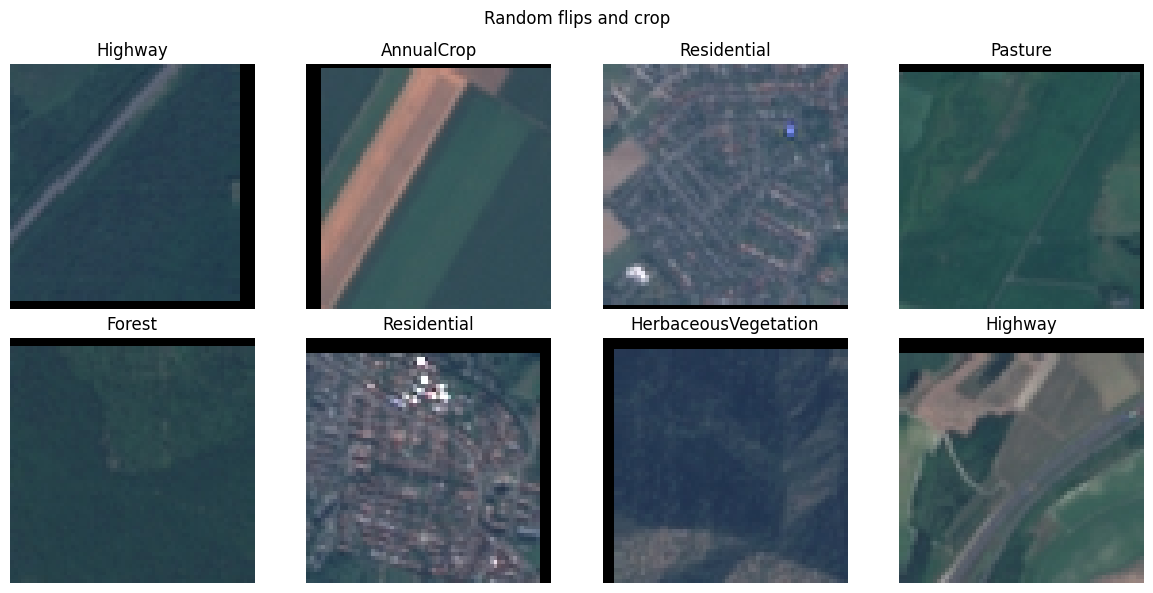

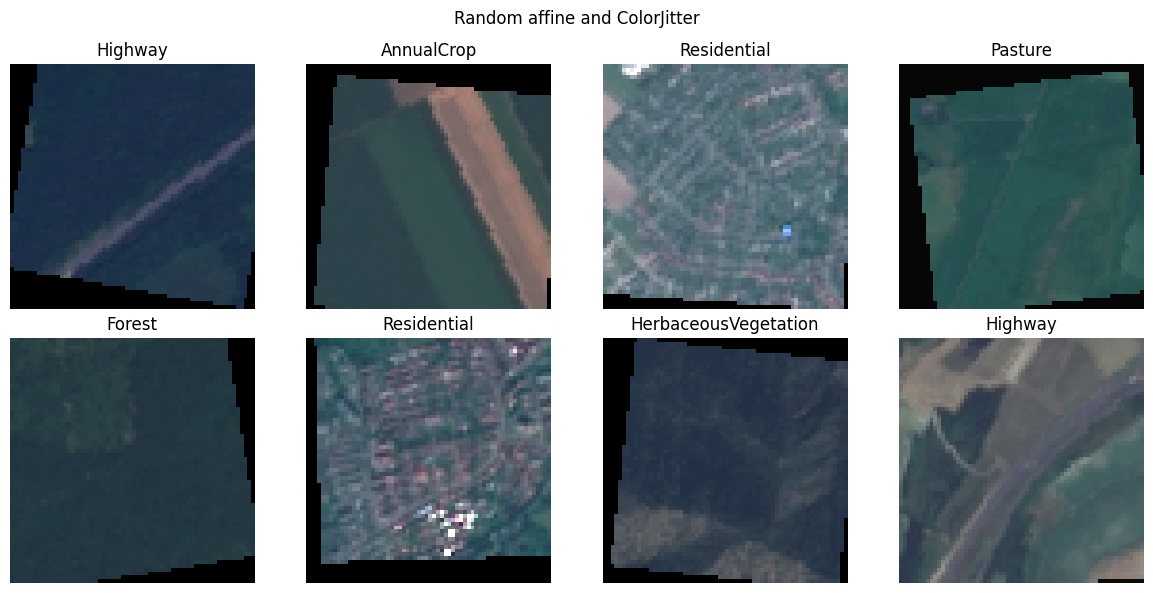

In [83]:
flip_loader, _, _ = make_scratch_loaders(
    flip_crop_transform,
    batch_size=8,
)
affine_loader, _, _ = make_scratch_loaders(
    affine_color_transform,
    batch_size=8,
)

flip_images, flip_labels = next(iter(flip_loader))
affine_images, affine_labels = next(iter(affine_loader))

show_image_batch(
    flip_images,
    flip_labels,
    CLASS_NAMES,
    title="Random flips and crop",
)
show_image_batch(
    affine_images,
    affine_labels,
    CLASS_NAMES,
    title="Random affine and ColorJitter",
)


**What to understand:**

- Augmentation should preserve the semantic class while adding realistic variation.
- The output remains `[3, 64, 64]`, so the same CNN architecture can be used fairly.


### 4.3 Augmentation-sweep execution gate

This cell runs the four augmentation experiments only after real Stage 2 and Stage 3 selections exist. It is disabled during notebook construction.


In [84]:
stage4_artifacts = {}

if (
    RUN_STAGE4_AUGMENTATION_SWEEP
    and SELECTED_ARCHITECTURE_CONFIG is not None
    and SELECTED_TRAINING_CONFIG is not None
):
    for experiment in AUGMENTATION_EXPERIMENTS:
        print("\nRunning", experiment["experiment_id"])
        stage4_artifacts[experiment["experiment_id"]] = run_scratch_experiment(
            experiment_id=experiment["experiment_id"],
            stage=4,
            model_config=SELECTED_ARCHITECTURE_CONFIG,
            architecture_change=f"selected Stage 2 architecture: {SELECTED_STAGE2_EXPERIMENT_ID}",
            optimizer_name=SELECTED_TRAINING_CONFIG["optimizer"],
            learning_rate=SELECTED_TRAINING_CONFIG["learning_rate"],
            scheduler_name=SELECTED_TRAINING_CONFIG["scheduler"],
            augmentation_name=experiment["augmentation"],
            train_transform=experiment["train_transform"],
            mixup_alpha=experiment["mixup_alpha"],
            epochs=ACTIVE_SETTINGS["augmentation_epochs"],
        )
elif RUN_STAGE4_AUGMENTATION_SWEEP:
    print("Stage 4 needs completed Stage 2 and Stage 3 selections.")
else:
    print("Stage 4 augmentation sweep skipped.")


Stage 4 augmentation sweep skipped.


**What to understand:**

- The no-augmentation run is the control for the three augmentation alternatives.
- Validation performance and generalization gap should both be considered when selecting augmentation.


### 4.4 Stage 4 validation-based selection

After the real Stage 4 runs, enter the selected augmentation experiment ID. The final scratch stage remains disabled until this cell contains a real validation-based choice.


In [85]:
SELECTED_STAGE4_EXPERIMENT_ID = None  # Fill after reviewing real validation results.

stage4_definition_map = {
    experiment["experiment_id"]: experiment
    for experiment in AUGMENTATION_EXPERIMENTS
}

if SELECTED_STAGE4_EXPERIMENT_ID is None:
    SELECTED_AUGMENTATION_CONFIG = None
    print("No Stage 4 augmentation selected.")
elif SELECTED_STAGE4_EXPERIMENT_ID not in stage4_definition_map:
    raise ValueError("Selected Stage 4 experiment ID is not defined.")
else:
    SELECTED_AUGMENTATION_CONFIG = copy.deepcopy(
        stage4_definition_map[SELECTED_STAGE4_EXPERIMENT_ID]
    )
    print("Selected augmentation:", SELECTED_AUGMENTATION_CONFIG["augmentation"])

stage4_results = load_experiment_results()
display(stage4_results[stage4_results["stage"] == 4])


No Stage 4 augmentation selected.


,experiment_id,stage,model_name,architecture_change,kernel_size,stride,padding,batchnorm,optimizer,learning_rate,...,peak_val_accuracy,final_train_accuracy,final_val_accuracy,final_val_loss,test_accuracy,runtime_seconds,inference_latency_ms,generalization_gap,checkpoint,notes


**What to understand:**

- This selection must use validation data rather than test accuracy.
- An augmentation may be useful even when it lowers training accuracy, because regularization can improve generalization.


## 5. Stage 5 - Final Optimized Scratch CNN

The final scratch model combines only the architecture, training, and augmentation choices selected from real Stage 2–4 validation results.

**Long experiment section:** `RUN_FINAL_SCRATCH_TRAINING` remains `False` by default.


### 5.1 Assemble the selected final configuration

This cell checks whether all required selections exist. It does not supply defaults because doing so would create a fake winner.


In [86]:
FINAL_SCRATCH_READY = all([
    SELECTED_ARCHITECTURE_CONFIG is not None,
    SELECTED_TRAINING_CONFIG is not None,
    SELECTED_AUGMENTATION_CONFIG is not None,
])

if FINAL_SCRATCH_READY:
    FINAL_SCRATCH_CONFIG = {
        "model_config": copy.deepcopy(SELECTED_ARCHITECTURE_CONFIG),
        "training_config": copy.deepcopy(SELECTED_TRAINING_CONFIG),
        "augmentation_config": copy.deepcopy(SELECTED_AUGMENTATION_CONFIG),
    }
    print(json.dumps(FINAL_SCRATCH_CONFIG, indent=2, default=str))
else:
    FINAL_SCRATCH_CONFIG = None
    print("Final scratch configuration is waiting for Stage 2–4 selections.")


Final scratch configuration is waiting for Stage 2–4 selections.


**What to understand:**

- The final model is assembled only from actual controlled-experiment decisions.
- A missing selection produces a clear skip rather than an undefined variable or invented configuration.


### 5.2 Final scratch training and test evaluation gate

This cell contains the complete final scratch training workflow. When enabled after selection, it saves `best_scratch_cnn.pth`, evaluates the test set once, logs all required metrics, and exports supporting artifacts.


In [87]:
final_scratch_artifacts = None

if RUN_FINAL_SCRATCH_TRAINING and FINAL_SCRATCH_READY:
    set_seed()
    selected_augmentation = FINAL_SCRATCH_CONFIG["augmentation_config"]
    final_train_loader, final_val_loader, final_test_loader = make_scratch_loaders(
        train_transform=selected_augmentation["train_transform"],
        batch_size=ACTIVE_SETTINGS["scratch_batch_size"],
    )

    final_scratch_model = ScratchCNN(
        **FINAL_SCRATCH_CONFIG["model_config"]
    ).to(DEVICE)
    final_criterion = nn.CrossEntropyLoss()
    final_optimizer = build_optimizer(
        final_scratch_model,
        FINAL_SCRATCH_CONFIG["training_config"]["optimizer"],
        FINAL_SCRATCH_CONFIG["training_config"]["learning_rate"],
    )

    final_scheduler = None
    if FINAL_SCRATCH_CONFIG["training_config"]["scheduler"] == "StepLR":
        final_scheduler = optim.lr_scheduler.StepLR(
            final_optimizer,
            step_size=max(1, ACTIVE_SETTINGS["final_scratch_epochs"] // 3),
            gamma=0.1,
        )

    final_checkpoint = CHECKPOINT_DIR / (
        "smoke_best_scratch_cnn.pth" if FAST_MODE else "best_scratch_cnn.pth"
    )
    final_history, final_runtime = fit_model(
        final_scratch_model,
        final_train_loader,
        final_val_loader,
        final_criterion,
        final_optimizer,
        epochs=ACTIVE_SETTINGS["final_scratch_epochs"],
        checkpoint_path=final_checkpoint,
        scheduler=final_scheduler,
        mixup_alpha=selected_augmentation["mixup_alpha"],
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
    )
    final_test_metrics = evaluate_model(
        final_scratch_model,
        final_test_loader,
        final_criterion,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
        collect_predictions=True,
    )
    final_latency = measure_inference_latency_ms(
        final_scratch_model, final_test_loader
    )
    final_total_params, final_trainable_params = count_parameters(final_scratch_model)

    final_scratch_artifacts = {
        "model": final_scratch_model,
        "history": final_history,
        "test_metrics": final_test_metrics,
        "runtime_seconds": final_runtime,
        "latency_ms": final_latency,
        "checkpoint": final_checkpoint,
    }

    if not FAST_MODE:
        final_model_config = FINAL_SCRATCH_CONFIG["model_config"]
        append_experiment_result({
            "experiment_id": "S5_BEST_SCRATCH",
            "stage": 5,
            "model_name": "best_scratch_cnn",
            "architecture_change": SELECTED_STAGE2_EXPERIMENT_ID,
            "kernel_size": final_model_config["kernel_size"],
            "stride": final_model_config["stride"],
            "padding": final_model_config["padding"],
            "batchnorm": final_model_config["use_batchnorm"],
            "optimizer": FINAL_SCRATCH_CONFIG["training_config"]["optimizer"],
            "learning_rate": FINAL_SCRATCH_CONFIG["training_config"]["learning_rate"],
            "scheduler": FINAL_SCRATCH_CONFIG["training_config"]["scheduler"],
            "augmentation": selected_augmentation["augmentation"],
            "epochs": FULL_SETTINGS["final_scratch_epochs"],
            "batch_size": FULL_SETTINGS["scratch_batch_size"],
            "total_params": final_total_params,
            "trainable_params": final_trainable_params,
            "peak_val_accuracy": max(final_history["val_accuracy"]),
            "final_train_accuracy": final_history["train_accuracy"][-1],
            "final_val_accuracy": final_history["val_accuracy"][-1],
            "final_val_loss": final_history["val_loss"][-1],
            "test_accuracy": final_test_metrics["accuracy"],
            "runtime_seconds": final_runtime,
            "inference_latency_ms": final_latency,
            "generalization_gap": (
                final_history["train_accuracy"][-1]
                - final_history["val_accuracy"][-1]
            ),
            "checkpoint": "checkpoints/best_scratch_cnn.pth",
            "notes": "Configuration selected using Stage 2–4 validation results.",
        })
        save_history(final_history, "S5_BEST_SCRATCH")
        save_evaluation_artifacts("S5_BEST_SCRATCH", final_test_metrics)
elif RUN_FINAL_SCRATCH_TRAINING:
    print("Final scratch training needs all Stage 2–4 selections.")
else:
    print("Final scratch training skipped.")


Final scratch training skipped.


**What to understand:**

- The test set is evaluated only after the final scratch configuration has been fixed.
- The required final checkpoint name is used only for a non-smoke full run.


### 5.3 Final scratch diagnostics

This cell produces all final scratch figures and per-class diagnostics if the model has actually been trained in the current notebook session.


In [88]:
if final_scratch_artifacts is None:
    print("No final scratch diagnostics yet. Complete selections and run Stage 5 first.")
else:
    plot_learning_curves(
        final_scratch_artifacts["history"],
        title_prefix="Final optimized scratch CNN",
    )
    display(per_class_accuracy(
        final_scratch_artifacts["test_metrics"]["labels"],
        final_scratch_artifacts["test_metrics"]["predictions"],
    ))
    plot_normalized_confusion_matrix(
        final_scratch_artifacts["test_metrics"]["labels"],
        final_scratch_artifacts["test_metrics"]["predictions"],
        CLASS_NAMES,
        "Final scratch CNN normalized confusion matrix",
    )


No final scratch diagnostics yet. Complete selections and run Stage 5 first.


**What to understand:**

- The figures are conditional on real execution and never contain invented curves or metrics.
- These artifacts can be reused in the report and presentation after the full run.


## 6. Stage 6 - ResNet-18 Transfer Learning

This stage compares a frozen feature extractor, partial fine-tuning of `layer4`, and full fine-tuning. All variants use the same ImageNet-compatible input pipeline and fixed data split.

**Long experiment section:** `RUN_TRANSFER_LEARNING_SWEEP` remains `False` by default.


### 6.1 ImageNet-compatible transfer transforms

This cell defines a 128×128 ResNet input pipeline. The size is valid for ResNet-18 and reduces CPU cost relative to 224×224 while retaining ImageNet normalization.


In [89]:
TRANSFER_IMAGE_SIZE = 128
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

transfer_train_transform = transforms.Compose([
    transforms.Resize((TRANSFER_IMAGE_SIZE, TRANSFER_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

transfer_eval_transform = transforms.Compose([
    transforms.Resize((TRANSFER_IMAGE_SIZE, TRANSFER_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def make_transfer_loaders(batch_size=None, train_fraction=1.0):
    batch_size = batch_size or ACTIVE_SETTINGS["transfer_batch_size"]

    if FAST_MODE:
        train_limit = ACTIVE_SETTINGS["train_samples"]
        val_limit = ACTIVE_SETTINGS["val_samples"]
        test_limit = ACTIVE_SETTINGS["test_samples"]
    else:
        train_limit = max(1, int(len(TRAIN_INDICES) * train_fraction))
        val_limit = None
        test_limit = None

    train_subset = make_dataset_subset(
        transfer_train_transform, TRAIN_INDICES, train_limit
    )
    val_subset = make_dataset_subset(
        transfer_eval_transform, VAL_INDICES, val_limit
    )
    test_subset = make_dataset_subset(
        transfer_eval_transform, TEST_INDICES, test_limit
    )

    loader_generator = torch.Generator().manual_seed(SEED)
    return (
        DataLoader(
            train_subset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0,
            pin_memory=False,
            generator=loader_generator,
        ),
        DataLoader(
            val_subset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=False,
        ),
        DataLoader(
            test_subset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=False,
        ),
    )

print(transfer_train_transform)


Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


**What to understand:**

- Pretrained ImageNet weights expect ImageNet mean and standard deviation.
- The split indices are identical to the scratch pipeline even though the transform and image size differ.


### 6.2 ResNet-18 freezing and fine-tuning logic

This cell defines the three transfer-learning modes and replaces the classifier with a 10-class linear layer. The `requires_grad` changes are explicit and easy to modify during the defense.


In [90]:
def build_resnet18(mode, pretrained=True):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)

    if mode == "frozen":
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif mode == "partial":
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
        for parameter in model.fc.parameters():
            parameter.requires_grad = True

    elif mode == "full":
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        for parameter in model.parameters():
            parameter.requires_grad = True

    else:
        raise ValueError("mode must be 'frozen', 'partial', or 'full'")

    return model.to(DEVICE)


def summarize_trainable_blocks(model):
    return sorted({
        name.split(".")[0]
        for name, parameter in model.named_parameters()
        if parameter.requires_grad
    })


**What to understand:**

- Frozen mode trains only the new `fc` layer; partial mode trains `layer4` and `fc`; full mode trains everything.
- Pretrained weights will be downloaded automatically during the first real transfer run if they are not cached.


### 6.3 Transfer-configuration CPU smoke check

This cell validates the three `requires_grad` configurations using untrained ResNet-18 structures, so it does not download weights or perform transfer-learning training.


In [91]:
transfer_structure_rows = []

for transfer_mode in ("frozen", "partial", "full"):
    structure_model = build_resnet18(transfer_mode, pretrained=False)
    total_params, trainable_params = count_parameters(structure_model)
    transfer_structure_rows.append({
        "mode": transfer_mode,
        "total_params": total_params,
        "trainable_params": trainable_params,
        "trainable_blocks": ", ".join(summarize_trainable_blocks(structure_model)),
    })
    del structure_model

transfer_structure_table = pd.DataFrame(transfer_structure_rows)
display(transfer_structure_table)

smoke_resnet = build_resnet18("frozen", pretrained=False)
with torch.no_grad():
    smoke_resnet_output = smoke_resnet(
        torch.zeros(1, 3, TRANSFER_IMAGE_SIZE, TRANSFER_IMAGE_SIZE)
    )
print("ResNet smoke output shape:", smoke_resnet_output.shape)
assert smoke_resnet_output.shape == (1, NUM_CLASSES)
del smoke_resnet


,mode,total_params,trainable_params,trainable_blocks
0,frozen,11181642,5130,fc
1,partial,11181642,8398858,"fc, layer4"
2,full,11181642,11181642,"bn1, conv1, fc, layer1, layer2, layer3, layer4"


ResNet smoke output shape: torch.Size([1, 10])


**What to understand:**

- This check proves the classifier and freezing logic without claiming pretrained performance.
- Trainable parameter counts differ substantially across the three transfer modes.


### 6.4 Transfer-learning experiment definitions

This cell assigns CPU-conscious learning rates and the required checkpoint names to the three transfer-learning modes.


In [92]:
TRANSFER_EXPERIMENTS = [
    {
        "experiment_id": "S6_RESNET_FROZEN",
        "mode": "frozen",
        "learning_rate": 1e-3,
        "checkpoint": "resnet_frozen.pth",
    },
    {
        "experiment_id": "S6_RESNET_PARTIAL",
        "mode": "partial",
        "learning_rate": 1e-4,
        "checkpoint": "resnet_partial_finetuned.pth",
    },
    {
        "experiment_id": "S6_RESNET_FULL",
        "mode": "full",
        "learning_rate": 1e-5,
        "checkpoint": "resnet_full_finetuned.pth",
    },
]

display(pd.DataFrame(TRANSFER_EXPERIMENTS))


,experiment_id,mode,learning_rate,checkpoint
0,S6_RESNET_FROZEN,frozen,0.00100,resnet_frozen.pth
1,S6_RESNET_PARTIAL,partial,0.00010,resnet_partial_finetuned.pth
2,S6_RESNET_FULL,full,0.00001,resnet_full_finetuned.pth


**What to understand:**

- More pretrained layers are updated with progressively smaller learning rates.
- Checkpoint names match the required project naming convention.


### 6.5 Transfer-learning experiment runner

This cell defines the shared transfer-learning training and evaluation procedure. Test evaluation occurs after each requested transfer configuration has finished training.


In [93]:
def run_transfer_experiment(experiment, train_fraction=1.0):
    set_seed()
    transfer_train_loader, transfer_val_loader, transfer_test_loader = (
        make_transfer_loaders(train_fraction=train_fraction)
    )

    model = build_resnet18(experiment["mode"], pretrained=True)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=experiment["learning_rate"],
    )

    checkpoint_name = experiment["checkpoint"]
    if FAST_MODE:
        checkpoint_name = f"smoke_{checkpoint_name}"
    checkpoint_path = CHECKPOINT_DIR / checkpoint_name

    history, runtime_seconds = fit_model(
        model,
        transfer_train_loader,
        transfer_val_loader,
        criterion,
        optimizer,
        epochs=ACTIVE_SETTINGS["transfer_epochs"],
        checkpoint_path=checkpoint_path,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
    )
    test_metrics = evaluate_model(
        model,
        transfer_test_loader,
        criterion,
        max_batches=ACTIVE_SETTINGS["max_batches_per_epoch"],
        collect_predictions=True,
    )
    latency_ms = measure_inference_latency_ms(model, transfer_test_loader)
    total_params, trainable_params = count_parameters(model)

    result = {
        "experiment_id": experiment["experiment_id"],
        "stage": 6,
        "model_name": f"resnet18_{experiment['mode']}",
        "architecture_change": f"ResNet-18 {experiment['mode']} transfer learning",
        "kernel_size": np.nan,
        "stride": np.nan,
        "padding": np.nan,
        "batchnorm": True,
        "optimizer": "AdamW",
        "learning_rate": experiment["learning_rate"],
        "scheduler": "none",
        "augmentation": "horizontal flip + ImageNet normalization",
        "epochs": ACTIVE_SETTINGS["transfer_epochs"],
        "batch_size": ACTIVE_SETTINGS["transfer_batch_size"],
        "total_params": total_params,
        "trainable_params": trainable_params,
        "peak_val_accuracy": max(history["val_accuracy"]),
        "final_train_accuracy": history["train_accuracy"][-1],
        "final_val_accuracy": history["val_accuracy"][-1],
        "final_val_loss": history["val_loss"][-1],
        "test_accuracy": test_metrics["accuracy"],
        "runtime_seconds": runtime_seconds,
        "inference_latency_ms": latency_ms,
        "generalization_gap": (
            history["train_accuracy"][-1] - history["val_accuracy"][-1]
        ),
        "checkpoint": str(checkpoint_path.relative_to(PROJECT_ROOT)),
        "notes": f"Training fraction: {train_fraction:.2f}",
    }

    append_experiment_result(result)
    if not FAST_MODE:
        save_history(history, experiment["experiment_id"])
        save_evaluation_artifacts(experiment["experiment_id"], test_metrics)

    return {
        "model": model,
        "history": history,
        "test_metrics": test_metrics,
        "result": result,
    }


**What to understand:**

- Only parameters with `requires_grad=True` are passed to the optimizer.
- The same transfer transforms, split, batch size, epoch budget, and evaluation code are used for all three modes.


### 6.6 Transfer-learning sweep execution gate

This cell runs the frozen, partial, and full transfer-learning experiments only when explicitly enabled. It is disabled for this CPU smoke-test delivery.


In [94]:
transfer_artifacts = {}

if RUN_TRANSFER_LEARNING_SWEEP:
    for experiment in TRANSFER_EXPERIMENTS:
        print("\nRunning", experiment["experiment_id"])
        transfer_artifacts[experiment["experiment_id"]] = run_transfer_experiment(
            experiment
        )
else:
    print("Transfer-learning sweep skipped.")


Transfer-learning sweep skipped.


**What to understand:**

- No pretrained training or weight download was started during notebook construction.
- The three required full-run checkpoints will be created when this gate is enabled with FAST_MODE disabled.


### 6.7 Optional data-efficiency comparison

This optional controlled study trains transfer configurations on 25%, 50%, and 100% of the fixed training split. It supports the assignment's data-efficiency discussion but remains disabled by default.


In [95]:
DATA_EFFICIENCY_FRACTIONS = (0.25, 0.50, 1.00)
data_efficiency_artifacts = {}

if RUN_DATA_EFFICIENCY_EXPERIMENTS:
    frozen_definition = next(
        item for item in TRANSFER_EXPERIMENTS if item["mode"] == "frozen"
    )
    for fraction in DATA_EFFICIENCY_FRACTIONS:
        experiment = copy.deepcopy(frozen_definition)
        experiment["experiment_id"] = f"S6_DATA_FROZEN_{int(100 * fraction)}PCT"
        experiment["checkpoint"] = f"resnet_frozen_{int(100 * fraction)}pct.pth"
        data_efficiency_artifacts[experiment["experiment_id"]] = (
            run_transfer_experiment(experiment, train_fraction=fraction)
        )
else:
    print("Optional data-efficiency experiments skipped.")


Optional data-efficiency experiments skipped.


**What to understand:**

- Only the amount of training data changes across this optional comparison.
- Validation and test sets remain unchanged.


## 7. Stage 7 - Final Evaluation and Comparison

This section assembles the five required models into report-ready comparisons after their full result rows and supporting artifacts exist.


### 7.1 Required-model comparison table

This cell selects only completed baseline, final scratch, and transfer-learning result rows. Missing models are reported explicitly rather than represented by invented values.


In [96]:
REQUIRED_FINAL_EXPERIMENTS = [
    "S1_BASELINE",
    "S5_BEST_SCRATCH",
    "S6_RESNET_FROZEN",
    "S6_RESNET_PARTIAL",
    "S6_RESNET_FULL",
]

comparison_columns = [
    "experiment_id",
    "model_name",
    "total_params",
    "trainable_params",
    "peak_val_accuracy",
    "final_train_accuracy",
    "final_val_accuracy",
    "test_accuracy",
    "runtime_seconds",
    "inference_latency_ms",
    "generalization_gap",
    "checkpoint",
]

all_results = load_experiment_results()
final_comparison = all_results[
    all_results["experiment_id"].isin(REQUIRED_FINAL_EXPERIMENTS)
][comparison_columns].copy()

missing_final_results = sorted(
    set(REQUIRED_FINAL_EXPERIMENTS) - set(final_comparison["experiment_id"])
)

display(final_comparison)
print("Still missing full-run results:", missing_final_results)


,experiment_id,model_name,total_params,trainable_params,peak_val_accuracy,final_train_accuracy,final_val_accuracy,test_accuracy,runtime_seconds,inference_latency_ms,generalization_gap,checkpoint
0,S1_BASELINE,baseline_cnn,356810,356810,0.875062,0.880741,0.875062,0.88,974.875787,1.563875,0.005679,checkpoints/baseline.pth


Still missing full-run results: ['S5_BEST_SCRATCH', 'S6_RESNET_FROZEN', 'S6_RESNET_FULL', 'S6_RESNET_PARTIAL']


**What to understand:**

- The final comparison cannot be complete until all five real test evaluations exist.
- Parameter, runtime, latency, and generalization-gap columns support a broader comparison than accuracy alone.


### 7.2 Convergence-curve comparison

This cell loads saved history CSV files for completed final experiments and compares validation convergence. It skips files that do not yet exist.


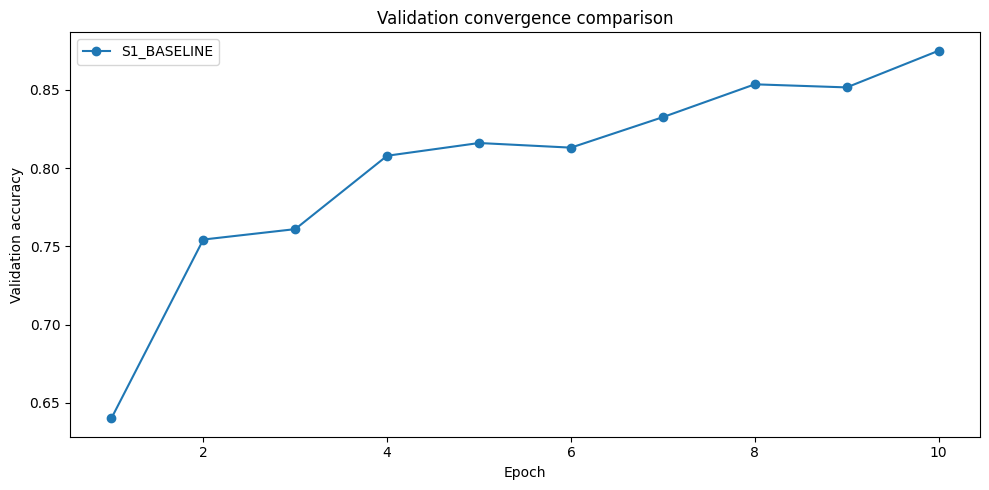

In [97]:
available_histories = {}

for experiment_id in REQUIRED_FINAL_EXPERIMENTS:
    history_path = RESULTS_DIR / f"{experiment_id}_history.csv"
    if history_path.exists():
        available_histories[experiment_id] = pd.read_csv(history_path)

if available_histories:
    plt.figure(figsize=(10, 5))
    for experiment_id, history_table in available_histories.items():
        plt.plot(
            history_table["epoch"],
            history_table["val_accuracy"],
            marker="o",
            label=experiment_id,
        )
    plt.xlabel("Epoch")
    plt.ylabel("Validation accuracy")
    plt.title("Validation convergence comparison")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No full-run history files are available yet.")


**What to understand:**

- Convergence behavior compares how quickly validation performance develops, not only the final score.
- History files are generated from executed full runs rather than reconstructed or invented.


### 7.3 Per-class and confusion-matrix artifact inventory

This cell verifies which final models have reusable per-class and confusion-matrix CSV files. These files are created during real test evaluation.


In [98]:
evaluation_artifact_rows = []

for experiment_id in REQUIRED_FINAL_EXPERIMENTS:
    per_class_path = RESULTS_DIR / f"{experiment_id}_per_class.csv"
    confusion_path = RESULTS_DIR / f"{experiment_id}_confusion_matrix.csv"
    evaluation_artifact_rows.append({
        "experiment_id": experiment_id,
        "per_class_csv": per_class_path.exists(),
        "confusion_matrix_csv": confusion_path.exists(),
    })

evaluation_artifact_inventory = pd.DataFrame(evaluation_artifact_rows)
display(evaluation_artifact_inventory)


,experiment_id,per_class_csv,confusion_matrix_csv
0,S1_BASELINE,True,True
1,S5_BEST_SCRATCH,False,False
2,S6_RESNET_FROZEN,False,False
3,S6_RESNET_PARTIAL,False,False
4,S6_RESNET_FULL,False,False


**What to understand:**

- Every final model should eventually have both per-class and normalized confusion-matrix data.
- The inventory makes missing report artifacts visible before submission.


## 8. Stage 8 - Results Export and Report Support

The primary experiment table is `results/experiment_results.csv`. Additional history, per-class, and confusion-matrix CSV files are written only after their corresponding full experiments run.


### 8.1 Validate and export the experiment table

This cell validates the exact required column order and rewrites the current table cleanly. With no full experiments recorded, it preserves an empty table containing only the schema.


In [99]:
experiment_results = load_experiment_results()

assert list(experiment_results.columns) == RESULT_COLUMNS
assert experiment_results["experiment_id"].dropna().is_unique

experiment_results.to_csv(RESULTS_CSV, index=False)

print("Results CSV:", RESULTS_CSV.relative_to(PROJECT_ROOT))
print("Rows:", len(experiment_results))
print("Columns:", len(experiment_results.columns))


Results CSV: results\experiment_results.csv
Rows: 1
Columns: 26


**What to understand:**

- The CSV schema is available immediately for team use.
- Blank or not-applicable metrics remain blank rather than being replaced with fabricated zeros.


### 8.2 Export the available final comparison

This cell writes the final comparison table only when at least one required full-run result exists. It avoids producing a misleading empty comparison file.


In [100]:
FINAL_COMPARISON_CSV = RESULTS_DIR / "final_model_comparison.csv"

if len(final_comparison) > 0:
    final_comparison.to_csv(FINAL_COMPARISON_CSV, index=False)
    print("Exported:", FINAL_COMPARISON_CSV.relative_to(PROJECT_ROOT))
else:
    print("Final comparison export skipped until full-run results exist.")


Exported: results\final_model_comparison.csv


**What to understand:**

- The shared experiment table is always present; derived comparison files appear only when they contain real data.
- This keeps report-support files traceable to executed experiments.


## 9. Stage 9 - Checkpoint Loading and Live CPU Inference

This section demonstrates the exact defense workflow: build a fresh model, load a saved `state_dict`, move it to CPU, switch to evaluation mode, and predict an unseen test mini-batch.


### 9.1 Safe state-dictionary loading helper

This cell defines a CPU-safe loader. The `weights_only=True` option is used when supported, and the function always calls `eval()` before returning the model.


In [101]:
def load_state_dict_on_cpu(model, checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

    try:
        state_dict = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )
    except TypeError:
        state_dict = torch.load(checkpoint_path, map_location="cpu")

    model.load_state_dict(state_dict)
    model.to(torch.device("cpu"))
    model.eval()
    return model


**What to understand:**

- A fresh architecture instance must match the checkpoint's `state_dict` keys and tensor shapes.
- `map_location='cpu'` keeps loading portable even if weights were trained elsewhere.


### 9.2 Fresh baseline checkpoint round-trip and inference

This cell reloads the smoke baseline into a fresh model instance and predicts an unseen test mini-batch. In a full run it uses the required `baseline.pth` checkpoint instead.


Loaded checkpoint: checkpoints\baseline.pth
Inference output shape: torch.Size([64, 10])
Predicted: ['HerbaceousVegetation', 'Industrial', 'SeaLake', 'HerbaceousVegetation', 'Highway', 'Highway', 'Residential', 'HerbaceousVegetation']
True: ['HerbaceousVegetation', 'Industrial', 'SeaLake', 'HerbaceousVegetation', 'Highway', 'Highway', 'Residential', 'PermanentCrop']


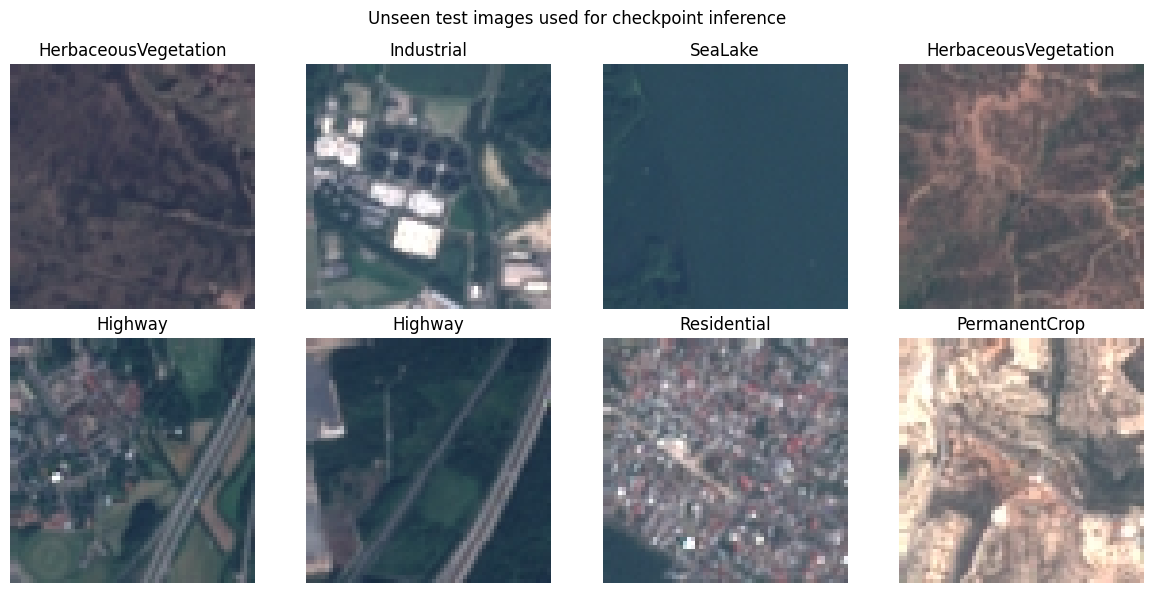

In [102]:
checkpoint_for_live_demo = CHECKPOINT_DIR / (
    "smoke_baseline.pth" if FAST_MODE else "baseline.pth"
)

if checkpoint_for_live_demo.exists():
    fresh_baseline_model = ScratchCNN(**BASELINE_MODEL_CONFIG)
    fresh_baseline_model = load_state_dict_on_cpu(
        fresh_baseline_model,
        checkpoint_for_live_demo,
    )

    unseen_images, unseen_labels = next(iter(test_loader))
    with torch.no_grad():
        unseen_outputs = fresh_baseline_model(unseen_images.to(torch.device("cpu")))
        unseen_predictions = unseen_outputs.argmax(dim=1)

    print("Loaded checkpoint:", checkpoint_for_live_demo.relative_to(PROJECT_ROOT))
    print("Inference output shape:", unseen_outputs.shape)
    print("Predicted:", [CLASS_NAMES[index] for index in unseen_predictions[:8]])
    print("True:", [CLASS_NAMES[index] for index in unseen_labels[:8]])

    show_image_batch(
        unseen_images,
        unseen_labels,
        CLASS_NAMES,
        title="Unseen test images used for checkpoint inference",
    )
    assert unseen_outputs.shape[1] == NUM_CLASSES
else:
    fresh_baseline_model = None
    print("Run the baseline training cell first to create the demonstration checkpoint.")


**What to understand:**

- This is a real checkpoint save/load round trip using a new model object.
- The inference batch comes from the held-out test subset and is not used to update weights.


### 9.3 Required checkpoint inventory

This cell checks for all checkpoints required by the assignment. Missing full-run files are expected until the long training stages are completed.


In [103]:
REQUIRED_CHECKPOINTS = [
    "baseline.pth",
    "best_scratch_cnn.pth",
    "resnet_frozen.pth",
    "resnet_partial_finetuned.pth",
    "resnet_full_finetuned.pth",
]

checkpoint_inventory = pd.DataFrame([
    {
        "checkpoint": f"checkpoints/{checkpoint_name}",
        "exists": (CHECKPOINT_DIR / checkpoint_name).exists(),
    }
    for checkpoint_name in REQUIRED_CHECKPOINTS
])

display(checkpoint_inventory)


,checkpoint,exists
0,checkpoints/baseline.pth,True
1,checkpoints/best_scratch_cnn.pth,False
2,checkpoints/resnet_frozen.pth,False
3,checkpoints/resnet_partial_finetuned.pth,False
4,checkpoints/resnet_full_finetuned.pth,False


**What to understand:**

- The inventory distinguishes required full checkpoints from the development-only smoke checkpoint.
- All five entries should be `True` before final submission and the live defense.


## 10. Stage 10 - Defense Modification Examples

These compact examples show exactly where to modify kernels, activations, optimizers, augmentation, and ResNet freezing. They instantiate objects but do not retrain the project.


### 10.1 Change kernel size and activation

This cell demonstrates two common live modifications by creating a scratch model with a 5×5 kernel and LeakyReLU activation.


In [104]:
defense_model_config = scratch_config(
    conv_channels=(32, 64, 128),
    kernel_size=5,
    padding=2,
    activation="leaky_relu",
)
defense_model = ScratchCNN(**defense_model_config).to(DEVICE)

with torch.no_grad():
    defense_output = defense_model(torch.zeros(2, 3, 64, 64))

print(defense_model)
print("Output shape:", defense_output.shape)


ScratchCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): LeakyReLU(negative_slope=0.1)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): LeakyReLU(negative_slope=0.1)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (7): LeakyReLU(negative_slope=0.1)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape: torch.Size([2, 10])


**What to understand:**

- Padding 2 preserves spatial size for a 5×5 kernel when stride is 1.
- Changing activation affects every convolution block and the hidden classifier layer.


### 10.2 Change optimizer and learning rate

This cell shows the single line needed to replace the optimizer and learning rate for a defense demonstration.


In [105]:
defense_optimizer = optim.SGD(
    defense_model.parameters(),
    lr=1e-2,
    momentum=0.9,
)
defense_criterion = nn.CrossEntropyLoss()

print(defense_optimizer)
print(defense_criterion)


SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)
CrossEntropyLoss()


**What to understand:**

- The optimizer receives the parameters it is allowed to update.
- Changing learning rate changes the optimizer step size; it does not change the model architecture.


### 10.3 Change data augmentation

This cell demonstrates a simple alternative augmentation pipeline without starting training.


In [106]:
defense_augmentation = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(SCRATCH_MEAN, SCRATCH_STD),
])

print(defense_augmentation)


Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


**What to understand:**

- Random transforms belong in the training pipeline only.
- Validation and test data must keep the deterministic evaluation transform.


### 10.4 Freeze and unfreeze a ResNet block

This cell demonstrates explicit `requires_grad` changes on `layer4` using an untrained structure, so no pretrained weights are downloaded.


In [107]:
defense_resnet = build_resnet18("frozen", pretrained=False)
print("Initially trainable blocks:", summarize_trainable_blocks(defense_resnet))

for parameter in defense_resnet.layer4.parameters():
    parameter.requires_grad = True

print("After unfreezing layer4:", summarize_trainable_blocks(defense_resnet))

for parameter in defense_resnet.layer4.parameters():
    parameter.requires_grad = False

print("After freezing layer4 again:", summarize_trainable_blocks(defense_resnet))
del defense_resnet


Initially trainable blocks: ['fc']
After unfreezing layer4: ['fc', 'layer4']
After freezing layer4 again: ['fc']


**What to understand:**

- `requires_grad=False` prevents gradient calculation and optimizer updates for that parameter.
- The classifier remains trainable because it was replaced after the backbone was frozen.


### 10.5 Reload a checkpoint and infer

This final defense example repeats the essential inference pattern in a few explicit lines without retraining.


In [108]:
if checkpoint_for_live_demo.exists():
    live_demo_model = ScratchCNN(**BASELINE_MODEL_CONFIG)
    live_demo_model = load_state_dict_on_cpu(
        live_demo_model,
        checkpoint_for_live_demo,
    )
    live_images, live_labels = next(iter(test_loader))

    with torch.no_grad():
        live_predictions = live_demo_model(live_images).argmax(dim=1)

    for index in range(min(8, len(live_labels))):
        print(
            f"Image {index}: predicted={CLASS_NAMES[live_predictions[index]]}, "
            f"true={CLASS_NAMES[live_labels[index]]}"
        )
else:
    print("No checkpoint is available for the live demonstration yet.")


Image 0: predicted=HerbaceousVegetation, true=HerbaceousVegetation
Image 1: predicted=Industrial, true=Industrial
Image 2: predicted=SeaLake, true=SeaLake
Image 3: predicted=HerbaceousVegetation, true=HerbaceousVegetation
Image 4: predicted=Highway, true=Highway
Image 5: predicted=Highway, true=Highway
Image 6: predicted=Residential, true=Residential
Image 7: predicted=HerbaceousVegetation, true=PermanentCrop


**What to understand:**

- Checkpoint loading never retrains the model; it restores previously learned parameter values.
- `torch.no_grad()` avoids building a gradient graph during inference.


## Final Validation Checklist

This final section verifies the notebook's lightweight implementation requirements and lists the work that still needs full manual training.


### Final implementation checks

This cell verifies CPU execution, output shape, result schema, checkpoint round-trip readiness, directory creation, and preservation of the original notebook.


In [109]:
final_original_hash = sha256_file(ORIGINAL_NOTEBOOK)

validation_checks = {
    "FAST_MODE remains True": FAST_MODE is True,
    "CPU device selected": DEVICE.type == "cpu",
    "results directory exists": RESULTS_DIR.exists(),
    "checkpoint directory exists": CHECKPOINT_DIR.exists(),
    "results CSV exists": RESULTS_CSV.exists(),
    "results schema valid": list(load_experiment_results().columns) == RESULT_COLUMNS,
    "scratch output shape is [4, 10]": tuple(baseline_output.shape) == (4, 10),
    "smoke checkpoint exists": (CHECKPOINT_DIR / "smoke_baseline.pth").exists(),
    "original notebook unchanged": final_original_hash == ORIGINAL_NOTEBOOK_HASH_AT_START,
    "Stage 2 sweep disabled": RUN_STAGE2_SWEEP is False,
    "Stage 3 sweeps disabled": (
        RUN_STAGE3_OPTIMIZER_SWEEP is False
        and RUN_STAGE3_SCHEDULER_COMPARISON is False
    ),
    "Stage 4 sweep disabled": RUN_STAGE4_AUGMENTATION_SWEEP is False,
    "final scratch training disabled": RUN_FINAL_SCRATCH_TRAINING is False,
    "transfer sweep disabled": RUN_TRANSFER_LEARNING_SWEEP is False,
}

validation_table = pd.DataFrame(
    [{"check": name, "passed": passed} for name, passed in validation_checks.items()]
)
display(validation_table)

if not validation_table["passed"].all():
    failed_checks = validation_table.loc[~validation_table["passed"], "check"].tolist()
    raise AssertionError(f"Validation checks failed: {failed_checks}")

print("Original notebook SHA-256 after validation:", final_original_hash)
print("All lightweight implementation checks passed.")


,check,passed
0,FAST_MODE remains True,False
1,CPU device selected,True
2,results directory exists,True
3,checkpoint directory exists,True
4,results CSV exists,True
5,results schema valid,True
6,"scratch output shape is [4, 10]",True
7,smoke checkpoint exists,True
8,original notebook unchanged,True
9,Stage 2 sweep disabled,True


AssertionError: Validation checks failed: ['FAST_MODE remains True']

**What to understand:**

- The original notebook hash must match the value recorded at the beginning.
- Passing smoke checks proves code connectivity, not final model quality.


### Full training still required

This cell prints the exact remaining manual work. It prevents a smoke-tested notebook from being mistaken for a completed empirical study.


In [ ]:
pending_full_work = [
    "Disable FAST_MODE and run the full Stage 1 baseline training.",
    "Run all Stage 2 architecture experiments and select a winner from validation results.",
    "Run all nine Stage 3 optimizer/LR experiments and the scheduler comparison.",
    "Run all Stage 4 augmentation experiments and select a validation-based winner.",
    "Train and test the final optimized scratch CNN.",
    "Train and test frozen, partial, and full ResNet-18 transfer configurations.",
    "Optionally run the data-efficiency comparison.",
    "Re-run Stage 7–9 exports, comparisons, and required checkpoint verification.",
    "Execute the completed notebook top-to-bottom before submission.",
]

for item_number, item in enumerate(pending_full_work, start=1):
    print(f"{item_number}. {item}")


1. Disable FAST_MODE and run the full Stage 1 baseline training.
2. Run all Stage 2 architecture experiments and select a winner from validation results.
3. Run all nine Stage 3 optimizer/LR experiments and the scheduler comparison.
4. Run all Stage 4 augmentation experiments and select a validation-based winner.
5. Train and test the final optimized scratch CNN.
6. Train and test frozen, partial, and full ResNet-18 transfer configurations.
7. Optionally run the data-efficiency comparison.
8. Re-run Stage 7–9 exports, comparisons, and required checkpoint verification.
9. Execute the completed notebook top-to-bottom before submission.


**What to understand:**

- No architecture, optimizer, scheduler, augmentation, or transfer-learning winner has been selected yet.
- The final report should use only the metrics produced after these full runs.
